# Is 2008's Liquidity / Credit-Spread Link a One-Off?
**CFM 301 – Reproducing slide 59 of Ch. 9 (Bonds) and testing whether it repeats in March 2020 and the 2022–23 rate shock**

**Research question.** *"Is 2008's near-perfect link between liquidity and credit spreads a one-off, or does it repeat in March 2020 (COVID) and the 2022–23 rate shock?"* Slide 59 (Baa–Treasury spread vs. a Treasury liquidity measure, Corr = 0.96, 2006–09) is the benchmark. We first reproduce and extend it (Sections 2–4), split the spread into liquidity and default risk and compare it with expected default losses (Sections 5–6), check sensitivity (Section 7), and then test recurrence directly with a design built for short, persistent samples (Section 8).

**Audience.** Central-bank and Treasury-market staff designing liquidity facilities (e.g. the 2020 corporate-credit facilities), who need to know whether a Treasury-liquidity indicator is a reliable guide to corporate-credit stress outside 2008; and corporate-bond fund managers, who need to know how much of the spread they earn is compensation for illiquidity rather than default risk.

**How to read this notebook.** Run top to bottom (Restart & Run All). Every code cell has a "What this does" markdown cell above it. All inputs are in `data/` (relative paths, no internet, no WRDS). Tables and figures are also written to `output/`.

| Section | Content | Assignment requirement |
|---|---|---|
| 1 | Question, audience, sources | Req. 1–2 |
| 2 | Loading, construction, cleaning, alignment | Req. 2–4 |
| 3 | Slide-59 figure and correlation, original and longest sample | Req. 5–6 |
| 4 | Comparison with the slide (including the slide's own chart data) | Req. 7 |
| 5 | Liquidity vs. default-risk regressions (Merton / VIX) | Req. 8 |
| 6 | Credit-spread puzzle | Req. 9 |
| 7 | Sensitivity: sub-periods, levels vs. changes, maturity, proxy, frequency, winsorizing | Req. 10 |
| **8** | **Does the link repeat in 2020 and 2022–23? Formal test and validation** | **Research question** |
| 9 | Conclusion and checklist | |

## 1. Sources and how each series is constructed (Req. 2)

| File in `data/` | Source | What it is | Used for |
|---|---|---|---|
| `BAA.csv` | FRED (Moody's) | Seasoned Baa corporate yield, **monthly average**, % per year. Moody's Baa bonds have maturities of **20 years and above** | Corporate side of the spread |
| `DBAA.csv` | FRED (Moody's) | Same series, **daily** | Daily-vs-monthly sensitivity; check that FRED's monthly series equals the monthly mean of the daily one |
| `tnc_qh_pars_1.xls` | US Treasury, TNC yield curve | Fitted **par yields on all outstanding Treasury coupon issues**, monthly average, %, maturities 2/3/5/7/10/20/30y, 1976–Sep 2026 | Treasury side of the spread (20-year = closest match to Baa); "off-the-run" side of the liquidity measure |
| `tnc_qh_otrpars.xls` | US Treasury, TNC yield curve | Fitted **par yields on on-the-run issues only**, monthly average, %, maturities 2/5/10y, 1986–Sep 2026 | "On-the-run" side of the liquidity measure |
| `GS10.csv`, `DGS10.csv`, `DGS20.csv`, `DGS30.csv` | FRED (Fed H.15) | Constant-maturity Treasury yields, monthly (GS10) and daily | Alternative Treasury maturities / frequency (sensitivity); `DGS20` has a long genuine data gap (cleaning example) |
| `VIXCLS.csv` | FRED (Cboe) | VIX, daily close, index points, from 1990 | Default-risk proxy (regressions) |
| `VXOCLS.csv` | FRED (Cboe) | VXO (old VIX), daily, 1986–Sep 2021 | Matches slide 51, which starts in 1986 (before VIX existed) |
| `TEDRATE.csv` | FRED | TED spread (3m LIBOR – 3m T-bill), daily, 1986–Jan 2022 | Alternative, funding-liquidity proxy (sensitivity and Section 8) |
| `slide59_cached_series.csv` | Lecture file `Ch 9 Bonds.pptx` (chart data cached in the slide; extracted once by `extract_slide59.py`) | The 46 monthly points slide 59 actually plots | Point-by-point comparison with the slide (Section 4.1) |

**Constructed series (all monthly, calendar-month label):**
* **Credit spread** `cs20` = Baa yield − 20-year Treasury par yield, in **percentage points** (pp). Main definition: Baa is a 20+-year index, so the 20-year Treasury is the best available maturity match. Alternatives: 10-year and 30-year TNC, and FRED's GS10.
* **Liquidity premium** `liq10` = 100 × (10-year **all-issue** par yield − 10-year **on-the-run** par yield), in **basis points** (bp). Seasoned (off-the-run) Treasuries yield more than the freshly issued on-the-run bond because investors pay up for the on-the-run's liquidity, so this is positive when liquidity is scarce. The slide labels the line "on-the-run minus off-the-run"; it plots the *size* of this gap, which is what we measure. CRSP Treasuries (which would give actual on/off-the-run bond pairs) is not available to us, so we use Treasury's fitted-curve version of the same idea. It is a *proxy*, not a verified copy of the lecture series.
* **VIX / VXO** = arithmetic mean of the observed daily closes in the month.
* **Frequency.** Everything is converted to **monthly averages** (all three monthly Treasury/Moody's sources are already monthly averages, so this keeps the definitions consistent). Month-end values are tested in Section 7.
* **Sample end.** The Treasury workbooks end in Sep 2026, so the analysis ends there (BAA exists to Oct 2026 and the daily files to early Nov 2026; the unfinished month is excluded).

### What this cell does
Imports packages, fixes relative paths, and sets up a **cleaning log**: every cleaning step records how many observations it touched (Req. 4: "report how many observations each step affects").

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

warnings.filterwarnings("ignore", message=".*xlrd engine is deprecated.*")   # legacy .xls reader still works
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

DATA = Path("../data")                       # the project-wide data folder (this notebook lives in neha/)
OUT = Path("output"); OUT.mkdir(exist_ok=True)   # tables / figures used in the report

CLEAN_LOG = []
def log_step(series, step, affected, total, note=""):
    CLEAN_LOG.append({"series": series, "step": step, "obs affected": int(affected), "of total": int(total), "note": note})

## 2. Load, clean and align (Req. 3–4)

### 2.1 FRED CSV files
**What this does.** `load_fred` reads each CSV *as text* so that FRED's blank / "." entries (holidays, days with no print) are visible, then: (1) parses dates (an invalid date would raise an error), (2) removes exact duplicate rows and stops with an error if two *different* values share a date, (3) converts blanks / "." to missing and drops them, and (4) logs the count at each step. No values are filled or interpolated: a missing day simply is not in the monthly average.

In [2]:
def load_fred(code):
    raw = pd.read_csv(DATA / f"{code}.csv", dtype=str)
    date_col, n_raw = raw.columns[0], len(raw)
    raw[date_col] = pd.to_datetime(raw[date_col])                      # raises on a malformed date
    n_exact = int(raw.duplicated().sum())
    raw = raw.drop_duplicates()
    if raw[date_col].duplicated().any():                               # same date, different value -> do not guess
        raise ValueError(f"{code}: conflicting duplicate dates")
    log_step(code, "exact duplicate rows removed", n_exact, n_raw)
    vals = pd.to_numeric(raw[code].replace({".": np.nan, "": np.nan}), errors="raise")
    s = pd.Series(vals.to_numpy(float), index=pd.DatetimeIndex(raw[date_col]), name=code).sort_index()
    log_step(code, "blank / '.' entries dropped (holidays, no print)", s.isna().sum(), len(s))
    return s.dropna()

FRED_CODES = ["BAA", "GS10", "DBAA", "DGS10", "DGS20", "DGS30", "VIXCLS", "VXOCLS", "TEDRATE"]
fred = {c: load_fred(c) for c in FRED_CODES}
cover = pd.DataFrame({c: {"first": s.index.min().date(), "last": s.index.max().date(), "valid obs": len(s)}
                      for c, s in fred.items()}).T
cover

,first,last,valid obs
BAA,1919-01-01,2026-10-01,1294
GS10,1953-04-01,2026-10-01,883
DBAA,1986-01-02,2026-11-04,10247
DGS10,1962-01-02,2026-11-04,16196
DGS20,1962-01-02,2026-11-04,14507
DGS30,1977-02-15,2026-11-04,12426
VIXCLS,1990-01-02,2026-11-05,9311
VXOCLS,1986-01-02,2021-09-23,9002
TEDRATE,1986-01-02,2022-01-21,8853


**What the log shows.** The monthly series (`BAA`, `GS10`) have no gaps. The daily series lose roughly 3–6 % of their rows to holidays / blank prints. `DGS20` loses far more (14 %): there is **no 20-year constant-maturity yield from Jan 1987 to Sep 1993** (81 months), a genuine gap rather than a holiday, which is why we do not use `DGS20` as the main Treasury series. The Treasury TNC workbooks below have no such gap.

### 2.2 Treasury TNC workbooks (`.xls`)
**What this does.** Each workbook has six title/spacer rows and an empty second column. We skip these, parse labels such as `Jan 1976` as months, convert yields to numbers, drop non-date rows and duplicates, and log the counts. Yields are in percent, the same unit as FRED.

In [3]:
def load_tnc(file, maturities):
    raw = pd.read_excel(DATA / file, sheet_name="Sheet1", header=None, skiprows=6).drop(columns=1)
    raw.columns = ["label"] + maturities
    n_raw = len(raw)
    dates = pd.to_datetime(raw["label"].astype(str).str.strip(), format="%b %Y", errors="coerce")
    log_step(file, "non-date / blank rows dropped", dates.isna().sum(), n_raw)
    raw, dates = raw[dates.notna()], dates[dates.notna()]
    vals = raw[maturities].apply(pd.to_numeric, errors="raise")
    df = vals.set_index(dates.dt.to_period("M")).sort_index()
    n_dup = int(df.index.duplicated().sum())
    log_step(file, "duplicate months removed", n_dup, len(df))
    df = df[~df.index.duplicated(keep="first")]
    log_step(file, "missing yields", df.isna().sum().sum(), df.size)
    return df

par = load_tnc("tnc_qh_pars_1.xls", ["t2", "t3", "t5", "t7", "t10", "t20", "t30"])   # all-issue (mostly off-the-run)
otr = load_tnc("tnc_qh_otrpars.xls", ["o2", "o5", "o10"])                           # on-the-run only
END = min(par.index.max(), otr.index.max())                                         # last month where the Treasury data exist
print(f"All-issue par yields : {par.index.min()} to {par.index.max()} ({len(par)} months)")
print(f"On-the-run par yields: {otr.index.min()} to {otr.index.max()} ({len(otr)} months)")
print("Analysis sample ends :", END)

All-issue par yields : 1976-01 to 2026-09 (609 months)
On-the-run par yields: 1986-01 to 2026-09 (489 months)
Analysis sample ends : 2026-09


### 2.3 Aligning everything to one monthly calendar
**What this does.** Builds the master monthly table `P` (Jan 1986 – last Treasury month; 1986 is the first month with Baa daily data and the first on-the-run yield):
* daily series → **monthly mean of observed days** (and, for the sensitivity analysis, the **last observed day** of the month);
* FRED monthly series and TNC monthly series are simply re-labelled to calendar months;
* spreads are formed in **percentage points** and the liquidity measure in **basis points** (×100), so units are explicit.

It then **validates the construction**: FRED's monthly Baa should equal the monthly mean of the daily Baa, and the Treasury's 10-year par yield should be close to FRED's constant-maturity 10-year.

In [4]:
def to_monthly(s, how="mean"):
    g = s.groupby(s.index.to_period("M"))
    return g.mean() if how == "mean" else g.last()

idx = pd.period_range("1986-01", END, freq="M")
P = pd.DataFrame(index=idx)
for c, name in [("BAA", "baa"), ("GS10", "gs10")]:
    P[name] = fred[c].set_axis(fred[c].index.to_period("M"))          # FRED monthly files: relabel to calendar month
for c, name in [("DBAA", "baa_d"), ("DGS10", "dgs10_d"), ("DGS20", "dgs20_d"), ("DGS30", "dgs30_d"),
                ("VIXCLS", "vix"), ("VXOCLS", "vxo"), ("TEDRATE", "ted_pp")]:
    P[name] = to_monthly(fred[c], "mean")                              # monthly mean of observed daily values
P = P.join(par).join(otr)

# --- constructed series -------------------------------------------------------------------
P["cs20"] = P["baa"] - P["t20"]            # MAIN credit spread (pp): Baa (20y+) minus 20y Treasury par yield
P["cs10"] = P["baa"] - P["t10"]            # alternatives: 10y / 30y TNC, and FRED GS10
P["cs30"] = P["baa"] - P["t30"]
P["cs2"] = P["baa"] - P["t2"]               # short-maturity comparison (used only to diagnose the slide levels)
P["cs5"] = P["baa"] - P["t5"]
P["cs10_gs"] = P["baa"] - P["gs10"]
P["cs20_cmt"] = P["baa"] - to_monthly(fred["DGS20"])          # FRED 20y CMT (has the 1987-93 gap)
P["liq10"] = 100 * (P["t10"] - P["o10"])   # MAIN liquidity premium (bp): all-issue minus on-the-run, 10y
P["liq5"] = 100 * (P["t5"] - P["o5"])      # alternative tenors
P["liq2"] = 100 * (P["t2"] - P["o2"])
P["ted"] = 100 * P["ted_pp"]               # TED spread in bp (funding-liquidity proxy)

# --- validation -----------------------------------------------------------------------------
chk = pd.DataFrame({
    "FRED monthly Baa - mean of daily Baa (pp)": (P["baa"] - P["baa_d"]).describe()[["mean", "min", "max"]],
    "FRED GS10 - mean of daily DGS10 (pp)":      (P["gs10"] - P["dgs10_d"]).describe()[["mean", "min", "max"]],
    "TNC 10y par - FRED GS10 (pp)":              (P["t10"] - P["gs10"]).describe()[["mean", "min", "max"]],
})
display(chk)
print(f"Master monthly table: {len(P)} months, {P.index.min()} to {P.index.max()}")
print("Months with the main spread AND the main liquidity measure:", P[["cs20", "liq10"]].dropna().shape[0])
print("Months with FRED DGS20 missing (the 1987-93 gap etc.):", int(P["cs20_cmt"].isna().sum()))
log_step("alignment", "months where the daily 20y CMT is unavailable (FRED DGS20 gap)", P["cs20_cmt"].isna().sum(), len(P),
         "main analysis uses the TNC 20y yield, which has no gap")
log_step("alignment", "months dropped: Treasury data end Sep 2026 (BAA / daily files run to Oct-Nov 2026)",
         (fred["BAA"].index.to_period("M") > END).sum(), len(fred["BAA"].index.to_period("M")))

,FRED monthly Baa - mean of daily Baa (pp),FRED GS10 - mean of daily DGS10 (pp),TNC 10y par - FRED GS10 (pp)
mean,-0.000,0.000,0.085
min,-0.013,-0.005,-0.210
max,0.005,0.005,0.610


Master monthly table: 489 months, 1986-01 to 2026-09
Months with the main spread AND the main liquidity measure: 489
Months with FRED DGS20 missing (the 1987-93 gap etc.): 81


**Reading the validation.** The FRED monthly Baa equals the monthly mean of the daily series to within rounding (so "monthly average" is the right description). The Treasury's all-issue 10-year par yield is on average about 8 bp above FRED's 10-year constant-maturity yield (CMT is based on the on-the-run bond) and diverges most in Dec 2008 – Feb 2009 (about +60 bp), which is already a sign of the on-the-run premium at work. So the TNC files are a sound replacement for FRED Treasuries and, unlike FRED, give a matched **20-year** yield with no gap and an on-the-run series.

### 2.4 Outliers: audit, then decide whether to winsorize
**What this does.** Flags any month more than 4 standard deviations from the series' own mean. **Nothing is removed here**, because in this project the crisis spikes (Oct 2008, Mar 2020, …) *are* the economic signal: slide 59 is about exactly those months. Winsorizing would flatten the very episodes we study, so the main results are **not winsorized**. Instead, Section 7 re-runs the key correlation with the data winsorized at 1/99 and 5/95 percent to show how much the extremes matter.

In [5]:
audit_cols = {"cs20": "Credit spread (pp)", "liq10": "Liquidity premium (bp)", "vix": "VIX", "vxo": "VXO", "ted": "TED (bp)"}
rows = []
for c, label in audit_cols.items():
    s = P[c].dropna()
    z = (s - s.mean()) / s.std()
    big = z[z.abs() > 4]
    rows.append({"series": label, "obs": len(s), "months beyond 4 sd": len(big),
                 "which months": ", ".join(str(m) for m in big.index[:8]) + (" ..." if len(big) > 8 else "")})
    log_step(c, "flagged beyond 4 sd (kept, not winsorized)", len(big), len(s), "crisis spikes are the signal")
display(pd.DataFrame(rows).set_index("series"))
print("Liquidity premium around March 2020 (bp):", P.loc["2020-02":"2020-04", "liq10"].round(0).to_dict())
print("Negative liquidity-gap months (on-the-run yield ABOVE the all-issue curve):", int((P["liq10"] < 0).sum()),
      "-> kept: a negative gap is information about the proxy (see Section 4), not a data error (Section 4)")

,obs,months beyond 4 sd,which months
series,,,
Credit spread (pp),489,7,"2008-10, 2008-11, 2008-12, 2009-01, 2009-02, 2..."
Liquidity premium (bp),489,4,"2008-11, 2008-12, 2009-01, 2009-02"
VIX,441,4,"2008-10, 2008-11, 2008-12, 2020-03"
VXO,429,5,"1987-10, 2008-10, 2008-11, 2008-12, 2020-03"
TED (bp),433,2,"1987-10, 2008-10"


Liquidity premium around March 2020 (bp): {Period('2020-02', 'M'): -2.0, Period('2020-03', 'M'): -1.0, Period('2020-04', 'M'): -3.0}
Negative liquidity-gap months (on-the-run yield ABOVE the all-issue curve): 72 -> kept: a negative gap is information about the proxy (see Section 4), not a data error (Section 4)


### 2.5 Cleaning log (Req. 4)
All cleaning steps and the number of observations each touched:

In [6]:
clean_df = pd.DataFrame(CLEAN_LOG)
clean_df.to_csv(OUT / "cleaning_log.csv", index=False)
clean_df   # rows with 0 affected are kept on purpose: they document that the check was run

,series,step,obs affected,of total,note
0,BAA,exact duplicate rows removed,0,1294,
1,BAA,"blank / '.' entries dropped (holidays, no print)",0,1294,
2,GS10,exact duplicate rows removed,0,883,
3,GS10,"blank / '.' entries dropped (holidays, no print)",0,883,
4,DBAA,exact duplicate rows removed,0,10655,
5,DBAA,"blank / '.' entries dropped (holidays, no print)",408,10655,
6,DGS10,exact duplicate rows removed,0,16917,
7,DGS10,"blank / '.' entries dropped (holidays, no print)",721,16917,
8,DGS20,exact duplicate rows removed,0,16917,
9,DGS20,"blank / '.' entries dropped (holidays, no print)",2410,16917,


## 3. Reproduce slide 59 (Req. 5–6)

**What this does.** Defines a dual-axis plotting helper that follows the slide's format (black solid = credit spread, left axis, %; red dashed = liquidity measure, right axis, bp) and a correlation helper. The correlation is the Pearson correlation of the two **levels** (as on the slide).

### 3.1 Original sample: Jan 2006 – Sep 2009
The slide's x-axis runs from 01-06 to about 07-09 in 3-month steps, i.e. about 45 monthly points. We use **Jan 2006 – Sep 2009 (N = 45)** and test the slide's possible end-point (through Dec 2009) in Section 7.

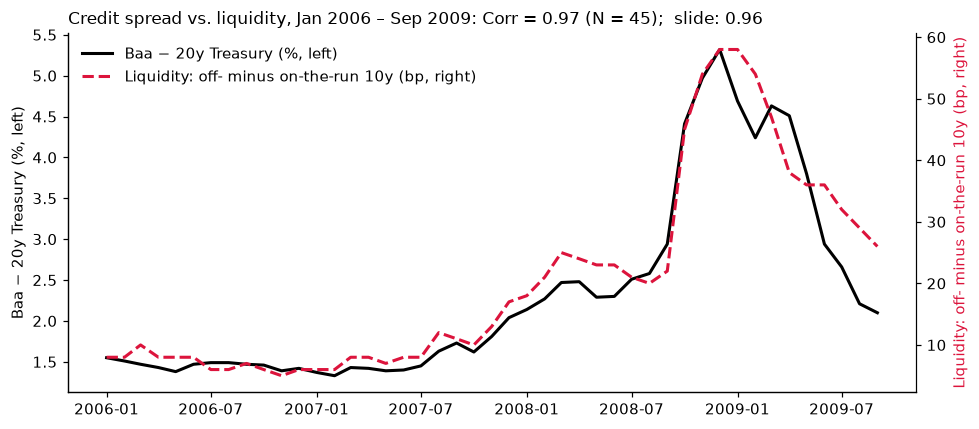

Original-sample correlation (levels): 0.967  (N = 45)


In [7]:
def corr(df, a, b):
    d = df[[a, b]].dropna()
    return d[a].corr(d[b]), len(d)

def dual_axis(ax, df, left, right, left_label, right_label, title):
    x = df.index.to_timestamp()
    l1, = ax.plot(x, df[left], color="black", lw=2, label=left_label)
    ax.set_ylabel(left_label)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
    l2, = ax2.plot(x, df[right], color="crimson", ls="--", lw=2, label=right_label)
    ax2.set_ylabel(right_label, color="crimson")
    ax.set_title(title, loc="left", fontsize=11)
    ax.legend(handles=[l1, l2], loc="upper left", frameon=False)
    return ax2

ORIG = P.loc["2006-01":"2009-09"]
r_orig, n_orig = corr(ORIG, "cs20", "liq10")
fig, ax = plt.subplots(figsize=(9, 4))
dual_axis(ax, ORIG, "cs20", "liq10", "Baa − 20y Treasury (%, left)", "Liquidity: off- minus on-the-run 10y (bp, right)",
          f"Credit spread vs. liquidity, Jan 2006 – Sep 2009: Corr = {r_orig:.2f} (N = {n_orig});  slide: 0.96")
fig.tight_layout(); fig.savefig(OUT / "fig1_slide59_reproduction.png"); plt.show()
print(f"Original-sample correlation (levels): {r_orig:.3f}  (N = {n_orig})")

### 3.2 Extended sample: longest overlap of the two series
**What this does.** The spread needs Baa and the 20-year Treasury (both back to 1976/1919) and the liquidity measure needs the on-the-run yield (from **Jan 1986**), so the longest sample is **Jan 1986 – Sep 2026**. The original window is shaded.

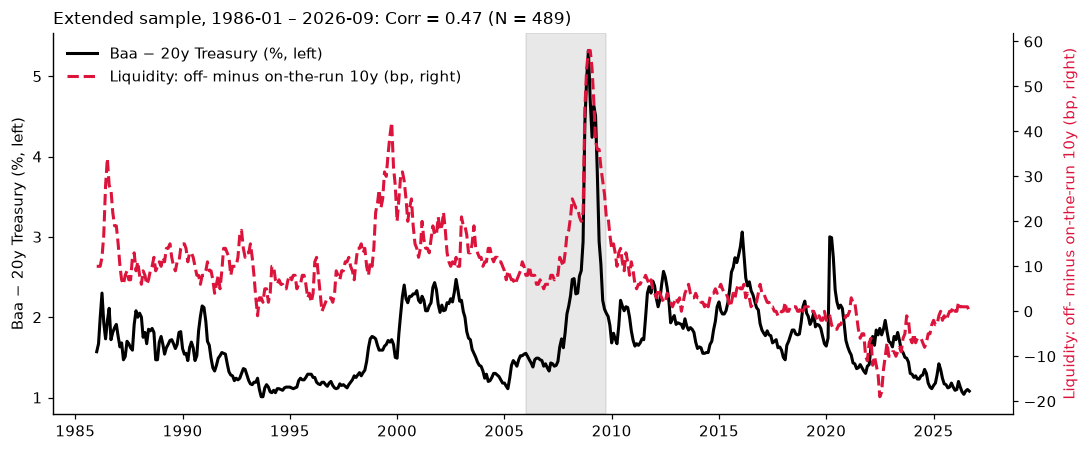

Extended-sample correlation (levels): 0.466  (N = 489)


In [8]:
FULL = P[["cs20", "liq10"]].dropna()
r_full, n_full = corr(FULL, "cs20", "liq10")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax2 = dual_axis(ax, FULL, "cs20", "liq10", "Baa − 20y Treasury (%, left)", "Liquidity: off- minus on-the-run 10y (bp, right)",
                f"Extended sample, {FULL.index.min()} – {FULL.index.max()}: Corr = {r_full:.2f} (N = {n_full})")
ax.axvspan(pd.Timestamp("2006-01-01"), pd.Timestamp("2009-09-30"), color="grey", alpha=0.18, label="slide-59 window")
fig.tight_layout(); fig.savefig(OUT / "fig2_extended_sample.png"); plt.show()
print(f"Extended-sample correlation (levels): {r_full:.3f}  (N = {n_full})")

## 4. Comparison with the slide (Req. 7)

**What this does.** (a) Checks that our *spread* is built correctly by comparing its 1987–2011 average with the lecture's 2.09 % (slide 44/55). (b) Reports the slide-window correlation for every plausible way of building the two series, since the slide does not say which Treasury maturity or liquidity definition it used. (c) Compares the *levels* we get with what the slide shows (~1 % in 2006 rising to ~8 % at the end of 2008).

In [9]:
# (a) spread-construction check against the lecture's Baa average spread, 1987-2011 (slide 44/55: 2.09%)
avg_8711 = P.loc["1987-01":"2011-12"]
print("Average Baa spread, Jan 1987 - Dec 2011 (slide: 2.09%)")
for c, lab in [("cs20", "Baa - 20y TNC"), ("cs10", "Baa - 10y TNC"), ("cs30", "Baa - 30y TNC"), ("cs10_gs", "Baa - GS10")]:
    print(f"  {lab:<16s}: {avg_8711[c].mean():.2f}%")

# (b) slide-window correlation for every spread / liquidity definition
rows = []
for sp, sp_lab in [("cs20", "Baa − 20y TNC (main)"), ("cs10", "Baa − 10y TNC"), ("cs30", "Baa − 30y TNC"), ("cs10_gs", "Baa − GS10 (FRED)"), ("cs20_cmt", "Baa − 20y CMT (FRED)")]:
    for lq, lq_lab in [("liq10", "10y gap (main)"), ("liq5", "5y gap"), ("liq2", "2y gap")]:
        r, n = corr(ORIG, sp, lq)
        rows.append({"credit spread": sp_lab, "liquidity measure": lq_lab, "Corr (Jan06-Sep09)": r, "N": n})
cmp_df = pd.DataFrame(rows).pivot(index="credit spread", columns="liquidity measure", values="Corr (Jan06-Sep09)")
display(cmp_df.loc[["Baa − 20y TNC (main)", "Baa − 10y TNC", "Baa − 30y TNC", "Baa − GS10 (FRED)", "Baa − 20y CMT (FRED)"], ["10y gap (main)", "5y gap", "2y gap"]])

# (c) levels vs what the slide shows: ~1% in 2006 rising to ~8% in late 2008; lecture's 1987-2011 average 2.09%
cands = {"Baa − 20y TNC (main)": "cs20", "Baa − 10y TNC": "cs10", "Baa − 5y TNC": "cs5", "Baa − 2y TNC": "cs2"}
lv = pd.DataFrame({lab: {"Jan 2006 (%)": ORIG.loc["2006-01", c], "peak in window (%)": ORIG[c].max(), "month of peak": str(ORIG[c].idxmax()),
                         "avg 1987–2011 (%) [slide 2.09]": P.loc["1987-01":"2011-12", c].mean(),
                         "Corr with 10y liquidity gap": ORIG[c].corr(ORIG["liq10"])} for lab, c in cands.items()}).T
display(lv)
print(f"Liquidity premium (bp): Jan 2006 = {ORIG.loc['2006-01','liq10']:.0f}, peak = {ORIG['liq10'].max():.0f} in {ORIG['liq10'].idxmax()}, Sep 2009 = {ORIG.loc['2009-09','liq10']:.0f}")
cmp_df.to_csv(OUT / "table_slide_window_corr_by_definition.csv")

Average Baa spread, Jan 1987 - Dec 2011 (slide: 2.09%)
  Baa - 20y TNC   : 1.71%
  Baa - 10y TNC   : 2.12%
  Baa - 30y TNC   : 1.71%
  Baa - GS10      : 2.25%


liquidity measure,10y gap (main),5y gap,2y gap
credit spread,,,
Baa − 20y TNC (main),0.967,0.190,-0.600
Baa − 10y TNC,0.969,0.220,-0.538
Baa − 30y TNC,0.962,0.177,-0.620
Baa − GS10 (FRED),0.976,0.221,-0.551
Baa − 20y CMT (FRED),0.968,0.196,-0.593


,Jan 2006 (%),peak in window (%),month of peak,avg 1987–2011 (%) [slide 2.09],Corr with 10y liquidity gap
Baa − 20y TNC (main),1.550,5.320,2008-12,1.705,0.967
Baa − 10y TNC,1.740,5.400,2008-12,2.117,0.969
Baa − 5y TNC,1.900,6.980,2008-12,2.712,0.971
Baa − 2y TNC,1.820,8.150,2008-11,3.304,0.960


Liquidity premium (bp): Jan 2006 = 8, peak = 58 in 2009-01, Sep 2009 = 26


### 4.1 What the slide actually plots (its chart data is stored inside the lecture file)
**What this does.** A `.pptx` file keeps the plotted values of each chart. `extract_slide59.py` (a one-off helper, run once) copied the 46 monthly points of slide 59's chart (Jan 2006 – Oct 2009) into `data/slide59_cached_series.csv`. We compare them with our series point by point: (a) does the slide's own data give the 0.96? (b) how close is our liquidity proxy to the slide's liquidity line? (c) how does the slide's spread differ from ours in *levels*?

In [10]:
sl = pd.read_csv(DATA / "slide59_cached_series.csv")
sl.index = pd.PeriodIndex(sl.pop("month"), freq="M")
cmp = sl.join(P[["cs20", "cs10", "cs2", "cs10_gs", "liq10"]])

print(f"(a) Slide's own plotted data: Corr = {sl['slide_spread_pct'].corr(sl['slide_liquidity_bp']):.3f}  (N = {len(sl)}, {sl.index.min()} to {sl.index.max()});  title says 0.96")
print(f"(b) Slide liquidity line vs. our 10y gap:  corr = {cmp['slide_liquidity_bp'].corr(cmp['liq10']):.3f};  slide peak {cmp['slide_liquidity_bp'].max():.0f} bp ({cmp['slide_liquidity_bp'].idxmax()}),  ours {cmp['liq10'].max():.0f} bp ({cmp['liq10'].idxmax()})")
rows = {}
for c, lab in [("cs20", "Baa − 20y TNC (main)"), ("cs10", "Baa − 10y TNC"), ("cs10_gs", "Baa − GS10"), ("cs2", "Baa − 2y TNC")]:
    slope, icpt = np.polyfit(cmp[c], cmp["slide_spread_pct"], 1)
    rows[lab] = {"corr with slide spread": cmp["slide_spread_pct"].corr(cmp[c]), "ours, Jan 2006": cmp[c].iloc[0], "slide, Jan 2006": cmp["slide_spread_pct"].iloc[0],
                 "ours, peak": cmp[c].max(), "slide, peak": cmp["slide_spread_pct"].max(),
                 "slide = a·ours + b: a": slope, "b": icpt}
display(pd.DataFrame(rows).T)

(a) Slide's own plotted data: Corr = 0.956  (N = 46, 2006-01 to 2009-10);  title says 0.96
(b) Slide liquidity line vs. our 10y gap:  corr = 0.956;  slide peak 65 bp (2009-01),  ours 58 bp (2009-01)


,corr with slide spread,"ours, Jan 2006","slide, Jan 2006","ours, peak","slide, peak",slide = a·ours + b: a,b
Baa − 20y TNC (main),0.983,1.550,1.180,5.320,7.920,1.831,-1.168
Baa − 10y TNC,0.988,1.740,1.180,5.400,7.920,1.729,-1.474
Baa − GS10,0.990,1.820,1.180,6.010,7.920,1.534,-1.279
Baa − 2y TNC,0.965,1.820,1.180,8.150,7.920,0.914,-0.407


### Findings: comparison with slide 59
* **The correlation reproduces.** Jan 2006 – Sep 2009 (N = 45): **0.967** vs. the slide's **0.96**. It is insensitive to how the series are built: 0.96–0.98 across five spread definitions (20y/10y/30y TNC, FRED GS10, FRED 20y CMT) when the liquidity measure is the 10-year gap. Ending the window in Dec 2009 instead of Sep 2009 (the slide's end-point is not exactly readable) gives 0.965 (Section 7.1).
* **Levels: the slide's spread is a more volatile series than any Treasury-maturity version of Moody's Baa.** The slide's own chart data peaks at **7.92 %** (Nov 2008) and starts at 1.18 % (Jan 2006); our Baa − 20y/10y/2y peaks at 5.0 / 5.4 / 8.2 % and starts at 1.55 / 1.74 / 1.82 %. Regressing the slide's spread on ours gives slopes of about 1.5–1.8 (the slide's spread swings roughly 1.5–1.8× as much), while the *shape* agrees almost perfectly (correlation 0.97–0.99 with every version). So the level gap cannot be fixed by changing the Treasury maturity (a 2-year Treasury happens to reproduce the 8 % peak but not the 2006 level or the shape); the slide most likely uses a different corporate index or spread definition (e.g. a bond-index spread), which it does not name. Two other level clues point in different directions (our Baa − 10y averages 2.12 % over 1987–2011, matching the lecture's 2.09 %, but our 20y version averages 1.71 %), so we do not claim to have identified it. This does not matter for the correlation, which is 0.96–0.97 for every construction, nor for the slide's own 0.956 (recomputed from its cached data).
* **The liquidity measure is a proxy.** Ours is the Treasury's fitted all-issue vs. on-the-run 10-year par-yield gap, not the yield difference of actual on/off-the-run bond pairs (CRSP Treasuries is not available). It is quoted to the nearest 1 bp, peaks at 58 bp (Jan 2009) versus 65 bp on the slide, but tracks the slide's liquidity line closely (corr 0.96), and is negative in 72 of 489 months, almost entirely from 2019 on (68 of the 72; average −11 bp in 2022), and about −1 bp in March 2020 even though Treasury market functioning was severely strained then. So the proxy is informative in 2008 but unreliable as a measure of liquidity in other episodes.
* **Extended sample (Jan 1986 – Sep 2026, N = 489): 0.466**, far below the slide-window 0.967. The extension therefore does *not* confirm a near-one-for-one link; Section 7 shows why.

## 5. Liquidity vs. default risk (Req. 8)

**Theory (slides 48–51).** In the Merton model a corporate bond = Treasury − put option on firm assets, so the credit spread is the value of that put. The put is worth more when asset **volatility** is higher, so spreads should widen when volatility rises. VIX (equity-market volatility) is our default-risk proxy. Liquidity is a separate, non-default component of the spread.

**What this does.** Regresses the monthly Baa spread (`cs20`, pp) on (A) the liquidity premium, (B) VIX, (C) both:
$$cs_t=a+b_L\,liq_t+b_V\,VIX_t+\varepsilon_t .$$
* **Sample:** Jan 1990 – Sep 2026 (VIX starts in 1990), identical months in all three models, N = 441.
* **t-statistics:** the series are highly persistent, so ordinary OLS t-stats overstate precision. We report both conventional t and **Newey-West HAC t (12 monthly lags)**.
* **Units:** $b_L$ = pp of spread per bp of liquidity; $b_V$ = pp of spread per VIX point.

In [11]:
def run_ols(df, y, xs, lags=12):
    d = df[[y] + xs].dropna()
    X = sm.add_constant(d[xs])
    ols = sm.OLS(d[y], X).fit()
    hac = sm.OLS(d[y], X).fit(cov_type="HAC", cov_kwds={"maxlags": lags, "use_correction": True})
    return d, ols, hac

NAMES = {"const": "Intercept (pp)", "liq10": "Liquidity premium (per bp)", "vix": "VIX (per point)"}
def reg_table(df, y="cs20", lags=12, models=None):
    models = models or {"A: liquidity": ["liq10"], "B: VIX": ["vix"], "C: both": ["liq10", "vix"]}
    # same months in every model
    base = df[[y, "liq10", "vix"]].dropna()
    out, fits = {}, {}
    for m, xs in models.items():
        d, ols, hac = run_ols(base, y, xs, lags)
        fits[m] = (ols, hac)
        col = {}
        for v in ["const", "liq10", "vix"]:
            if v in ols.params.index:
                col[NAMES[v]] = f"{ols.params[v]:.4f}  (t = {ols.tvalues[v]:.1f}; HAC t = {hac.tvalues[v]:.1f})"
            else:
                col[NAMES[v]] = ""
        col["R-squared"] = f"{ols.rsquared:.3f}"
        col["Observations"] = f"{int(ols.nobs)}"
        out[m] = col
    return pd.DataFrame(out), fits, base

REG = P.loc["1990-01":END]
tab_main, fits_main, base_main = reg_table(REG)
display(tab_main)
tab_main.to_csv(OUT / "table_regression_main_1990_2026.csv")

,A: liquidity,B: VIX,C: both
Intercept (pp),1.5345 (t = 50.4; HAC t = 15.1),0.7241 (t = 12.0; HAC t = 3.1),0.7903 (t = 13.2; HAC t = 4.4)
Liquidity premium (per bp),0.0262 (t = 11.3; HAC t = 2.1),,0.0122 (t = 5.6; HAC t = 1.8)
VIX (per point),,0.0520 (t = 17.9; HAC t = 4.0),0.0438 (t = 13.8; HAC t = 5.7)
R-squared,0.225,0.421,0.460
Observations,441,441,441


**Which factor explains more? Standardised coefficients and variance shares.**
The two regressors are in different units, so raw coefficients are not comparable. We (i) z-score all variables and re-run model C, and (ii) split the R² into the part unique to each factor and the part they share (A + B − C). Also reported: the correlation of the spread with VIX/VXO against slide 51 (Corr = 0.64, 1986–2013) and the same regressions on the slide-59 window.

In [12]:
# (i) standardised coefficients, model C
z = (base_main - base_main.mean()) / base_main.std()
_, ols_z, hac_z = run_ols(z, "cs20", ["liq10", "vix"])
std_tab = pd.DataFrame({"std. beta": ols_z.params[["liq10", "vix"]], "HAC t": hac_z.tvalues[["liq10", "vix"]]})
std_tab.index = ["Liquidity premium", "VIX"]
display(std_tab)

# (ii) R-squared split
R2A, R2B, R2C = (fits_main[m][0].rsquared for m in ["A: liquidity", "B: VIX", "C: both"])
split = pd.Series({"R² liquidity alone": R2A, "R² VIX alone": R2B, "R² both": R2C,
                   "unique to liquidity (C − B)": R2C - R2B, "unique to VIX (C − A)": R2C - R2A,
                   "shared (A + B − C)": R2A + R2B - R2C, "unexplained (1 − C)": 1 - R2C})
display(split.to_frame("share of variance"))
split.to_frame("share of variance").to_csv(OUT / "table_r2_split.csv")

# (iii) correlation with VIX / VXO vs. slide 51 (0.64, 1986-2013)
rows = []
for lab, (sp, vol, a, b) in {
    "Baa − GS10 vs VXO, 1986-2013 (slide 51 setup)": ("cs10_gs", "vxo", "1986-01", "2013-12"),
    "Baa − 20y TNC vs VXO, 1986-2013":               ("cs20", "vxo", "1986-01", "2013-12"),
    "Baa − GS10 vs VIX, 1990-2013":                  ("cs10_gs", "vix", "1990-01", "2013-12"),
    "Baa − 20y TNC vs VIX, 1990-2013":               ("cs20", "vix", "1990-01", "2013-12"),
    "Baa − 20y TNC vs VIX, 1990-2026 (our sample)":  ("cs20", "vix", "1990-01", str(END)),
}.items():
    r, n = corr(P.loc[a:b], sp, vol)
    rows.append({"pair": lab, "Corr": r, "N": n, "slide 51": 0.64 if "slide 51" in lab else np.nan})
corr_vix = pd.DataFrame(rows).set_index("pair"); display(corr_vix)
corr_vix.to_csv(OUT / "table_corr_vix.csv")

# (iv) the same three models on the slide-59 window and in first differences (robustness)
tab_orig, _, _ = reg_table(P.loc["2006-01":"2009-09"], lags=6)
print("Same models, Jan 2006 - Sep 2009 (HAC 6 lags):"); display(tab_orig)
dP = P.loc["1990-01":END, ["cs20", "liq10", "vix"]].diff().dropna()
tab_diff, _, _ = reg_table(dP)
print("Same models in monthly CHANGES, 1990-2026 (HAC 12 lags):"); display(tab_diff)
tab_orig.to_csv(OUT / "table_regression_2006_2009.csv"); tab_diff.to_csv(OUT / "table_regression_changes.csv")

,std. beta,HAC t
Liquidity premium,0.221,1.800
VIX,0.546,5.717


,share of variance
R² liquidity alone,0.225
R² VIX alone,0.421
R² both,0.460
unique to liquidity (C − B),0.038
unique to VIX (C − A),0.235
shared (A + B − C),0.187
unexplained (1 − C),0.540


,Corr,N,slide 51
pair,,,
"Baa − GS10 vs VXO, 1986-2013 (slide 51 setup)",0.623,336,0.640
"Baa − 20y TNC vs VXO, 1986-2013",0.704,336,NaN
"Baa − GS10 vs VIX, 1990-2013",0.707,288,NaN
"Baa − 20y TNC vs VIX, 1990-2013",0.764,288,NaN
"Baa − 20y TNC vs VIX, 1990-2026 (our sample)",0.649,441,NaN


Same models, Jan 2006 - Sep 2009 (HAC 6 lags):


,A: liquidity,B: VIX,C: both
Intercept (pp),0.8949 (t = 12.3; HAC t = 21.4),0.3759 (t = 3.0; HAC t = 2.4),0.6771 (t = 7.3; HAC t = 7.2)
Liquidity premium (per bp),0.0707 (t = 24.9; HAC t = 27.4),,0.0498 (t = 7.3; HAC t = 6.6)
VIX (per point),,0.0823 (t = 18.0; HAC t = 11.2),0.0271 (t = 3.3; HAC t = 3.0)
R-squared,0.935,0.883,0.949
Observations,45,45,45


Same models in monthly CHANGES, 1990-2026 (HAC 12 lags):


,A: liquidity,B: VIX,C: both
Intercept (pp),-0.0006 (t = -0.1; HAC t = -0.1),-0.0008 (t = -0.1; HAC t = -0.1),-0.0005 (t = -0.1; HAC t = -0.1)
Liquidity premium (per bp),0.0190 (t = 7.1; HAC t = 1.9),,0.0114 (t = 4.9; HAC t = 1.9)
VIX (per point),,0.0215 (t = 14.3; HAC t = 4.9),0.0197 (t = 13.0; HAC t = 6.0)
R-squared,0.104,0.319,0.354
Observations,440,440,440


### Findings: liquidity vs. default risk
* **VIX explains more of the spread than liquidity.** Jan 1990 – Sep 2026 (N = 441, identical months): R² = **0.225** (liquidity alone), **0.421** (VIX alone), **0.460** (both). Standardised coefficients in model C: 0.22 (liquidity) vs. 0.55 (VIX). Of the 46 % explained, 23.5 pp is unique to VIX, 3.8 pp is unique to liquidity and 18.7 pp is shared; 54 % is unexplained.
* **Signs match the Merton model.** The VIX coefficient is positive and strongly significant even with HAC errors (0.044 pp per VIX point in model C, HAC t = 5.7): when volatility rises, the put on firm assets is worth more and spreads widen. The liquidity coefficient is positive (0.012 pp per bp in model C) but only borderline significant once autocorrelation is accounted for (HAC t = 1.8; conventional t = 5.6 overstates it).
* **Slide 51 is reproduced.** Corr(Baa − Treasury, VIX) over our sample is **0.649** (slide: 0.64), and using the old VXO from 1986 as the slide does, Baa − GS10 vs. VXO over 1986–2013 gives 0.623.
* **In the 2006–09 crisis window the ranking flips**: liquidity R² = 0.935 vs. VIX R² = 0.883 (both: 0.949), but N = 45 and both series trend together, so this is a statement about one episode.
* **In monthly changes** the R²s fall to 0.104 (liquidity), 0.319 (VIX), 0.354 (both). VIX is again the dominant factor; liquidity adds only about 3.5 pp of explained variance.
* **Credit-spread puzzle (slide 54).** The lecture says default-risk variables explain about 25 % of spread *changes* (about 40 % with liquidity and macro added). Our VIX alone explains 32 % of monthly changes and 35 % together with liquidity: the same order of magnitude, though VIX is a broad measure that also carries risk aversion, not a pure default measure. The majority of spread variation is not explained by either factor.

## 6. The credit-spread puzzle (Req. 9)

**Expected default loss** = default probability × (1 − recovery rate). Inputs come from the lecture slides (Moody's data):

| Input | Value | Source |
|---|---|---|
| Baa annual credit-loss rate, 1982–2008 | 0.124 % | slide 55 (Moody's) |
| Average recovery rate | 41 % | slide 56 (Chen 2010) |
| Recovery in recessions | 20–25 % (we use 22.5 %) | slide 56 |
| Implied Baa annual default probability | 0.124 / (1 − 0.41) ≈ 0.21 % | derived |
| 150-year US corporates: default rate × loss-given-default | 1.5 % × 50 % = 0.75 % | slide 57 (Giesecke et al.) |

**What this does.** (a) Compares the average Baa spread in our sample with expected loss under three assumptions (average Baa; Baa with recession-level recovery; the all-grades 150-year figure, which is an upper reference for Baa). (b) Asks how much of the leftover ("residual") spread our liquidity evidence accounts for: liquidity part = $b_L\times$ average liquidity premium, using $b_L$ from the liquidity-only regression (upper bound; it also absorbs anything correlated with liquidity) and from the model that also controls for VIX (lower bound). (c) Repeats the split by period and draws a stacked bar like slide 58.

In [13]:
LOSS_BAA, REC_AVG, REC_RECESSION = 0.124, 0.41, 0.225          # slide 55 / 56
PD_BAA = LOSS_BAA / (1 - REC_AVG)                              # implied annual default prob. (%)
EL = {"Baa, average recovery (41%)": PD_BAA * (1 - REC_AVG),
      "Baa, recession recovery (22.5%)": PD_BAA * (1 - REC_RECESSION),
      "150-yr all-grade benchmark (1.5% x 50%)": 1.5 * 0.5}

bL_A = fits_main["A: liquidity"][0].params["liq10"]            # liquidity-only slope (pp per bp)
bL_C = fits_main["C: both"][0].params["liq10"]                 # slope controlling for VIX
avg_spread = REG["cs20"].mean(); avg_liq = REG["liq10"].mean()
print(f"Implied Baa default probability: {PD_BAA:.3f}%  | sample {REG.index.min()}-{REG.index.max()}: avg spread {avg_spread:.2f} pp, avg liquidity {avg_liq:.1f} bp")

rows = []
for lab, el in EL.items():
    resid = avg_spread - el
    rows.append({"expected-loss assumption": lab, "avg spread (pp)": avg_spread, "expected loss (pp)": el,
                 "spread / loss (x)": avg_spread / el, "residual (pp)": resid,
                 "liquidity part, b_L(A) (pp)": bL_A * avg_liq, "liquidity part, b_L(C) (pp)": bL_C * avg_liq,
                 "share of residual, upper": bL_A * avg_liq / resid, "share of residual, lower": bL_C * avg_liq / resid})
puzzle = pd.DataFrame(rows).set_index("expected-loss assumption")
display(puzzle.T)
puzzle.to_csv(OUT / "table_puzzle_decomposition.csv")

# the same arithmetic with the 10y-matched spread, whose 1987-2011 average matches the lecture's 2.09%
alt = pd.DataFrame({lab: {"avg spread 1990-2026 (pp)": REG[c].mean(), "expected loss (pp)": LOSS_BAA, "spread / loss (x)": REG[c].mean() / LOSS_BAA,
                          "residual (pp)": REG[c].mean() - LOSS_BAA, "avg spread 1987-2011 (pp)": P.loc["1987-01":"2011-12", c].mean(),
                          "1987-2011 spread / loss (x) [slide 17x]": P.loc["1987-01":"2011-12", c].mean() / LOSS_BAA}
                    for lab, c in {"Baa − 20y TNC (main)": "cs20", "Baa − 10y TNC": "cs10"}.items()})
print("Spread / loss with two maturity matches:"); display(alt)
# like the lecture: same-window check, spread averaged over 1987-2011 (slide: 2.09 / 0.124 = 17x)
s8711 = P.loc["1987-01":"2011-12", "cs20"].mean()
print(f"1987-2011 average Baa-20y spread {s8711:.2f}% vs slide 2.09%;  spread / 0.124% loss = {s8711/LOSS_BAA:.0f}x (slide: 17x)")

Implied Baa default probability: 0.210%  | sample 1990-01-2026-09: avg spread 1.73 pp, avg liquidity 7.6 bp


expected-loss assumption,"Baa, average recovery (41%)","Baa, recession recovery (22.5%)",150-yr all-grade benchmark (1.5% x 50%)
avg spread (pp),1.734,1.734,1.734
expected loss (pp),0.124,0.163,0.750
spread / loss (x),13.987,10.649,2.313
residual (pp),1.610,1.572,0.984
"liquidity part, b_L(A) (pp)",0.200,0.200,0.200
"liquidity part, b_L(C) (pp)",0.093,0.093,0.093
"share of residual, upper",0.124,0.127,0.203
"share of residual, lower",0.058,0.059,0.095


Spread / loss with two maturity matches:


,Baa − 20y TNC (main),Baa − 10y TNC
avg spread 1990-2026 (pp),1.734,2.199
expected loss (pp),0.124,0.124
spread / loss (x),13.987,17.736
residual (pp),1.610,2.075
avg spread 1987-2011 (pp),1.705,2.117
1987-2011 spread / loss (x) [slide 17x],13.752,17.070


1987-2011 average Baa-20y spread 1.71% vs slide 2.09%;  spread / 0.124% loss = 14x (slide: 17x)


,avg spread,expected loss,liquidity (b_L x avg liq),"rest (risk pay, taxes, options, other)",avg liquidity (bp)
period,,,,,
1990–2007,1.521,0.124,0.307,1.090,11.690
GFC 2008–09,3.101,0.163,0.840,2.098,32.042
2010–19,1.989,0.124,0.096,1.769,3.642
COVID 2020–21,1.823,0.163,-0.073,1.733,-2.792
2022–26,1.395,0.124,-0.138,1.410,-5.281


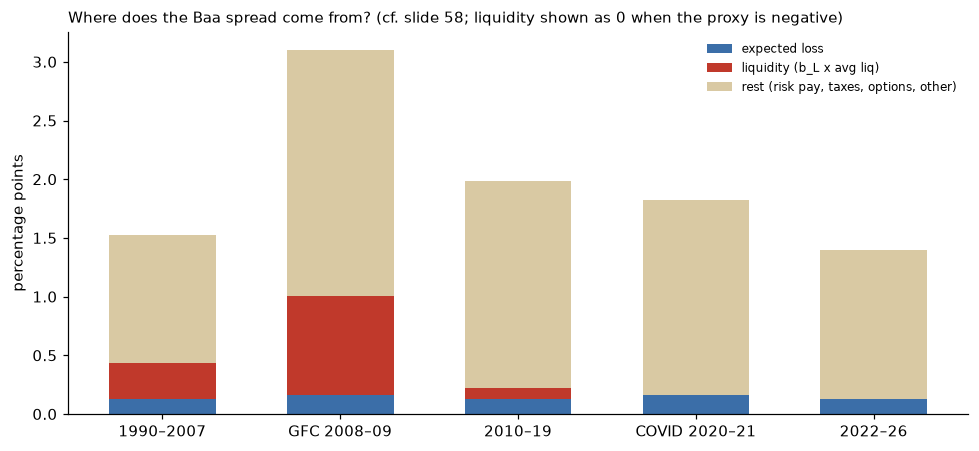

In [14]:
# (c) by period, stacked like slide 58: expected loss | liquidity (b_L(A) x mean liquidity) | the rest
periods = {"1990–2007": ("1990-01", "2007-12"), "GFC 2008–09": ("2008-01", "2009-12"), "2010–19": ("2010-01", "2019-12"),
           "COVID 2020–21": ("2020-01", "2021-12"), "2022–26": ("2022-01", str(END))}
rec_periods = {"GFC 2008–09", "COVID 2020–21"}                 # recession-level recovery assumed in these windows
rows = []
for lab, (a, b) in periods.items():
    w = REG.loc[a:b]
    el = PD_BAA * (1 - (REC_RECESSION if lab in rec_periods else REC_AVG))
    liq_part = bL_A * w["liq10"].mean()
    rows.append({"period": lab, "avg spread": w["cs20"].mean(), "expected loss": el, "liquidity (b_L x avg liq)": liq_part,
                 "rest (risk pay, taxes, options, other)": w["cs20"].mean() - el - liq_part, "avg liquidity (bp)": w["liq10"].mean()})
per = pd.DataFrame(rows).set_index("period"); display(per); per.to_csv(OUT / "table_period_decomposition.csv")

# For the figure only: a negative liquidity contribution (proxy below zero, 2020 onward) is drawn as 0 so each bar sums to the actual spread;
# the table above keeps the raw (negative) values.
plot = per.copy()
plot["liquidity (b_L x avg liq)"] = plot["liquidity (b_L x avg liq)"].clip(lower=0)
plot["rest (risk pay, taxes, options, other)"] = plot["avg spread"] - plot["expected loss"] - plot["liquidity (b_L x avg liq)"]
fig, ax = plt.subplots(figsize=(9, 4.2))
parts = ["expected loss", "liquidity (b_L x avg liq)", "rest (risk pay, taxes, options, other)"]
cols = ["#3b6ea8", "#c0392b", "#d9c9a3"]
xs_ = np.arange(len(plot)); bottom = np.zeros(len(plot))
for p_, c_ in zip(parts, cols):
    ax.bar(xs_, plot[p_], bottom=bottom, color=c_, label=p_, width=0.6); bottom += plot[p_].to_numpy()
ax.set_xticks(xs_, plot.index); ax.set_ylabel("percentage points")
ax.set_title("Where does the Baa spread come from? (cf. slide 58; liquidity shown as 0 when the proxy is negative)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(OUT / "fig3_spread_decomposition.png"); plt.show()

### Findings: credit-spread puzzle
* **Expected default loss is tiny relative to the spread.** Average Baa − 20y spread, 1990–2026 = **1.73 pp**; expected loss = 0.124 pp (default probability ≈ 0.21 % × 59 % loss), so the spread is about **14×** the expected loss and **1.61 pp** is left over. Using recession-level recovery (22.5 %) raises the loss only to 0.163 pp (leftover 1.57 pp). Even the 150-year all-grade benchmark (0.75 pp, an upper reference for Baa) leaves 0.98 pp. With the 10-year-matched spread the ratio is 17.1× for 1987–2011, as on slide 55.
* **Liquidity accounts for only a small share of the leftover.** Using the liquidity-only slope, the average liquidity premium (7.6 bp) contributes **0.20 pp**, i.e. about **12 %** of the 1.61 pp residual (upper bound); controlling for VIX the figure is 0.09 pp, about **6 %** (lower bound). The rest is a default-risk *premium* (defaults cluster in recessions, recoveries fall), taxes, embedded options and other factors, which our data cannot separate.
* **Crisis vs. normal.** In 2008–09 the liquidity part is about 0.84 pp of a 3.10 pp spread (27 %); in 1990–2007 and 2010–19 it is 0.3 pp or less, and in 2020–26 the proxy is negative so its contribution is non-positive. This matches the lecture's message (slide 58) that illiquidity is a large part of spreads in a crisis but a small part in normal times, and that expected losses are a thin slice throughout.
* *Caveats:* the decomposition is a static accounting exercise on an average, not a causal one (the liquidity slope also absorbs anything correlated with it); expected loss uses historical Moody's averages that understate losses in downturns; and the liquidity proxy is imperfect.

## 7. Sensitivity analysis (Req. 10)

A level correlation of two persistent series that both spiked in one crisis can be very high without telling us much, so we re-compute the correlation under alternative assumptions, one definition at a time:

* **7.1 Sub-periods** (crisis vs. non-crisis) and **levels vs. changes** (monthly first differences, computed *within* each window).
* **7.2 Treasury maturity** and **liquidity proxy** (10/5/2-year gap, TED spread).
* **7.3 Data frequency** (daily vs. monthly average vs. month-end) and **winsorizing**.
* **7.4 Rolling 36-month correlation** to see how stable the relationship is through time.

### 7.1 Sub-periods, levels vs. changes
**What this does.** For each window it reports the correlation of the main spread with the main liquidity premium in levels and in monthly changes. `Full excl. 2007–09` removes the crisis entirely.

In [15]:
def lvl_chg(df, a="cs20", b="liq10"):
    d = df[[a, b]].dropna()
    dd = d.diff().dropna()                                      # changes formed inside the window
    return {"N (levels)": len(d), "Corr levels": d[a].corr(d[b]), "Corr changes": dd[a].corr(dd[b]) if len(dd) > 3 else np.nan}

windows = {
    "Slide window 2006-01 → 2009-09": P.loc["2006-01":"2009-09"],
    "Slide window to Dec 2009":       P.loc["2006-01":"2009-12"],
    "GFC 2008-01 → 2009-12":          P.loc["2008-01":"2009-12"],
    "Pre-crisis 1986 → 2005":         P.loc["1986-01":"2005-12"],
    "Post-crisis 2010 → 2019":        P.loc["2010-01":"2019-12"],
    "COVID 2020 → 2021":              P.loc["2020-01":"2021-12"],
    "Rate shock 2022 → 2026-09":      P.loc["2022-01":END],
    "Full sample excl. 2007–09":      P.drop(P.loc["2007-01":"2009-12"].index),
    "Full sample 1986 → 2026-09":     P,
}
s71 = pd.DataFrame({k: lvl_chg(v) for k, v in windows.items()}).T
s71["N (levels)"] = s71["N (levels)"].astype(int)
display(s71); s71.to_csv(OUT / "table_sens_subperiods.csv")

,N (levels),Corr levels,Corr changes
Slide window 2006-01 → 2009-09,45,0.967,0.698
Slide window to Dec 2009,48,0.965,0.691
GFC 2008-01 → 2009-12,24,0.933,0.692
Pre-crisis 1986 → 2005,240,0.482,0.057
Post-crisis 2010 → 2019,120,0.137,0.073
COVID 2020 → 2021,24,0.084,0.098
Rate shock 2022 → 2026-09,57,-0.828,-0.030
Full sample excl. 2007–09,453,0.109,0.066
Full sample 1986 → 2026-09,489,0.466,0.277


### 7.2 Treasury maturity and liquidity proxy
**What this does.** Re-computes the correlation (levels and changes) for each alternative Treasury maturity (spread side) against the main liquidity premium, and for each alternative liquidity proxy (liquidity side) against the main spread. The TED spread is a *funding-liquidity* measure that only runs to Jan 2022. Shown for the slide window and the full overlap of each pair.

In [16]:
rows = []
for sp, sp_lab in [("cs20", "Baa − 20y TNC (main)"), ("cs2", "Baa − 2y TNC"), ("cs10", "Baa − 10y TNC"), ("cs30", "Baa − 30y TNC"), ("cs10_gs", "Baa − 10y FRED GS10")]:
    rows.append({"change": "Treasury maturity", "variant": sp_lab,
                 **{f"{lab} {k}": v for lab, w in [("slide", P.loc["2006-01":"2009-09"]), ("full", P)] for k, v in
                    {"levels": lvl_chg(w, sp, "liq10")["Corr levels"], "changes": lvl_chg(w, sp, "liq10")["Corr changes"]}.items()}})
for lq, lq_lab in [("liq10", "10y gap (main)"), ("liq5", "5y gap"), ("liq2", "2y gap"), ("ted", "TED spread (to Jan 2022)")]:
    rows.append({"change": "Liquidity proxy", "variant": lq_lab,
                 **{f"{lab} {k}": v for lab, w in [("slide", P.loc["2006-01":"2009-09"]), ("full", P)] for k, v in
                    {"levels": lvl_chg(w, "cs20", lq)["Corr levels"], "changes": lvl_chg(w, "cs20", lq)["Corr changes"]}.items()}})
s72 = pd.DataFrame(rows).set_index(["change", "variant"]); display(s72); s72.to_csv(OUT / "table_sens_maturity_proxy.csv")

slide levels  slide changes  full levels  full changes
change            variant                                                                         
Treasury maturity Baa − 20y TNC (main)             0.967          0.698        0.466         0.277
                  Baa − 2y TNC                     0.960          0.733        0.419         0.293
                  Baa − 10y TNC                    0.969          0.634        0.365         0.147
                  Baa − 30y TNC                    0.962          0.737        0.535         0.293
                  Baa − 10y FRED GS10              0.976          0.708        0.495         0.288
Liquidity proxy   10y gap (main)                   0.967          0.698        0.466         0.277
                  5y gap                           0.190         -0.026       -0.004         0.093
                  2y gap                          -0.600         -0.409       -0.082        -0.076
                  TED spread (to Jan 2022)         0.537          0.477        0.248         0.357

### 7.3 Frequency (daily vs. monthly, average vs. month-end) and winsorizing
**What this does.**
* **Daily vs. monthly.** The liquidity measure only exists monthly, so for the *daily* comparison we use the pair that is available every day: the Baa–10y Treasury spread (daily Moody's Baa minus daily 10-year CMT) against the daily VIX. We compare daily levels/changes with monthly-average and month-end levels/changes. Days where any of the three series is missing are dropped first (logged).
* **Monthly average vs. month-end for the liquidity pair.** The spread built from month-end daily values (10-year) vs. the monthly-average liquidity premium.
* **Winsorizing.** The slide-window and full-sample correlation after clipping both series at the 1st/99th and 5th/95th percentiles (of the window used).

In [17]:
# ---- daily panel: keep only days where Baa, 10y CMT and VIX are all observed --------------
D = pd.concat([fred["DBAA"], fred["DGS10"], fred["VIXCLS"]], axis=1, sort=True)
D = D[(D.index >= "1990-01-01") & (D.index <= END.end_time)]
n_union = len(D); D = D.dropna()
log_step("daily panel", "days dropped: one of Baa / 10y CMT / VIX not observed (holiday mismatch)", n_union - len(D), n_union)
D["cs"] = D["DBAA"] - D["DGS10"]
M_avg = D.groupby(D.index.to_period("M")).mean()
M_end = D.groupby(D.index.to_period("M")).last()

def cc(x, y): return x.corr(y)
def freq_rows(lo, hi):
    d, ma, me = D.loc[lo:hi], M_avg.loc[lo:hi], M_end.loc[lo:hi]
    return {"daily levels": (cc(d["cs"], d["VIXCLS"]), len(d)),
            "daily changes": (cc(d["cs"].diff(), d["VIXCLS"].diff()), len(d) - 1),
            "monthly-avg levels": (cc(ma["cs"], ma["VIXCLS"]), len(ma)),
            "monthly-avg changes": (cc(ma["cs"].diff(), ma["VIXCLS"].diff()), len(ma) - 1),
            "month-end levels": (cc(me["cs"], me["VIXCLS"]), len(me)),
            "month-end changes": (cc(me["cs"].diff(), me["VIXCLS"].diff()), len(me) - 1)}
fa = pd.DataFrame({"1990 → 2026-09": freq_rows("1990-01-01", END.end_time), "2006 → 2009-09": freq_rows("2006-01-01", "2009-09-30")}).T
fa_corr = fa.map(lambda t: t[0]); fa_n = fa.map(lambda t: t[1])
print("(a) Baa − 10y CMT spread vs VIX: correlation by frequency"); display(fa_corr)
print("    number of observations"); display(fa_n.astype(int))

# month-end vs average spread against the (monthly-average) liquidity premium, slide window
w = ORIG.index
pair = pd.DataFrame({"cs10, monthly avg of daily": M_avg.loc[w[0]:w[-1], "cs"], "cs10, month-end": M_end.loc[w[0]:w[-1], "cs"]})
pair["liq10"] = P.loc[w, "liq10"]
print("(b) Slide window, spread (10y CMT) vs liquidity premium (monthly avg)")
display(pd.Series({"monthly avg spread": pair["cs10, monthly avg of daily"].corr(pair["liq10"]),
                   "month-end spread": pair["cs10, month-end"].corr(pair["liq10"])}).to_frame("Corr with liq10"))
fa_corr.to_csv(OUT / "table_sens_frequency.csv")

# ---- winsorizing -----------------------------------------------------------------------------
def wins(s, lo, hi): return s.clip(s.quantile(lo), s.quantile(hi))
rows = {}
for lab, w_ in [("slide window", P.loc["2006-01":"2009-09"]), ("full 1986-2026", P)]:
    d = w_[["cs20", "liq10"]].dropna()
    rows[lab] = {"no winsorizing (main)": d["cs20"].corr(d["liq10"]),
                 "1% / 99%": wins(d["cs20"], .01, .99).corr(wins(d["liq10"], .01, .99)),
                 "5% / 95%": wins(d["cs20"], .05, .95).corr(wins(d["liq10"], .05, .95))}
sw = pd.DataFrame(rows).T; print("(c) Correlation of levels after winsorizing both series"); display(sw); sw.to_csv(OUT / "table_sens_winsorize.csv")

(a) Baa − 10y CMT spread vs VIX: correlation by frequency


,daily levels,daily changes,monthly-avg levels,monthly-avg changes,month-end levels,month-end changes
1990 → 2026-09,0.607,0.150,0.631,0.557,0.615,0.440
2006 → 2009-09,0.904,0.243,0.925,0.661,0.939,0.658


    number of observations


,daily levels,daily changes,monthly-avg levels,monthly-avg changes,month-end levels,month-end changes
1990 → 2026-09,9174,9173,441,440,441,440
2006 → 2009-09,938,937,45,44,45,44


(b) Slide window, spread (10y CMT) vs liquidity premium (monthly avg)


,Corr with liq10
monthly avg spread,0.976
month-end spread,0.967


(c) Correlation of levels after winsorizing both series


,no winsorizing (main),1% / 99%,5% / 95%
slide window,0.967,0.967,0.967
full 1986-2026,0.466,0.427,0.279


### 7.4 Rolling 36-month correlation
**What this does.** Plots the correlation of levels over a moving 36-month window (and of monthly changes), to show whether the strong 2008 relationship is typical of other periods.

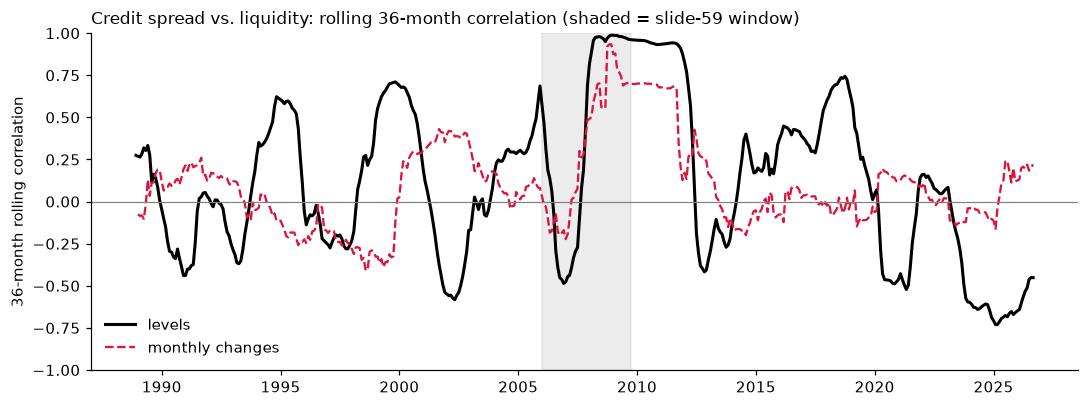

Share of 36-month windows with a level correlation above 0.5: 23%; above 0.8: 11%
Median rolling correlation: levels 0.11, changes 0.06


In [18]:
roll_lvl = P["cs20"].rolling(36).corr(P["liq10"])
roll_chg = P["cs20"].diff().rolling(36).corr(P["liq10"].diff())
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(roll_lvl.index.to_timestamp(), roll_lvl, color="black", lw=2, label="levels")
ax.plot(roll_chg.index.to_timestamp(), roll_chg, color="crimson", lw=1.5, ls="--", label="monthly changes")
ax.axhline(0, color="grey", lw=0.8); ax.axvspan(pd.Timestamp("2006-01-01"), pd.Timestamp("2009-09-30"), color="grey", alpha=0.15)
ax.set_ylim(-1, 1); ax.set_ylabel("36-month rolling correlation"); ax.legend(frameon=False, loc="lower left")
ax.set_title("Credit spread vs. liquidity: rolling 36-month correlation (shaded = slide-59 window)", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(OUT / "fig4_rolling_correlation.png"); plt.show()
share_pos = (roll_lvl.dropna() > 0.5).mean()
print(f"Share of 36-month windows with a level correlation above 0.5: {share_pos:.0%}; above 0.8: {(roll_lvl.dropna() > 0.8).mean():.0%}")
print(f"Median rolling correlation: levels {roll_lvl.median():.2f}, changes {roll_chg.median():.2f}")

### Findings: sensitivity
* **Sub-periods: the relationship is a crisis phenomenon.** Level correlation: **0.97** in the slide window (0.93 in 2008–09), but 0.48 in 1986–2005, 0.14 in 2010–19, 0.08 in 2020–21 and **−0.83** in 2022–26. Removing 2007–09 from the full sample cuts the correlation from 0.47 to **0.11**. The rolling 36-month correlation exceeds 0.5 in only 23 % of windows and 0.8 in 11 % (median 0.11).
* **Levels vs. changes.** In monthly changes the correlation is 0.70 in the slide window (0.28 full sample) and ≤ 0.10 in every other sub-period. Much of the 0.96 is therefore two persistent series that rise and fall together through one crisis, not month-to-month co-movement.
* **Treasury maturity does not matter for the correlation** (slide window 0.96–0.98 for 2y/10y/20y/30y; full sample 0.37–0.54). **The liquidity proxy does:** the 5-year gap gives 0.19 and the 2-year gap −0.60 in the slide window, and the TED spread (funding liquidity) gives 0.54. The headline result is specific to the 10-year on/off-the-run gap.
* **Frequency.** Baa − 10y vs. VIX: daily levels 0.61 vs. 0.63 monthly-average and 0.62 month-end (1990–2026); the level relationship is frequency-robust. Changes are not: 0.15 daily vs. 0.56 monthly-average and 0.44 month-end, because day-to-day noise washes out on aggregation. Average vs. month-end spread against the liquidity gap in the slide window: 0.976 vs. 0.967, so the convention is immaterial. The liquidity gap exists only monthly, so a daily liquidity test is not possible.
* **Winsorizing.** No effect in the slide window (0.967 → 0.967); in the full sample the correlation falls from 0.466 to 0.427 (1/99) and 0.279 (5/95), i.e. a large share of the full-sample correlation comes from the extreme crisis months, which is why the main analysis does not winsorize them.
* **Does the answer to the economic question change?** Yes. Within the slide window the near-perfect link holds under every definition. Outside it, the link is weak or even negative, it all but vanishes in monthly changes, and it depends on the proxy chosen.

## 8. The research question: is 2008's link a one-off, or does it repeat in March 2020 and 2022–23?

**Why this section is the core of the project.** Slide 59 shows a near-perfect link in one crisis. The group's research question is whether that link is a *general feature of crises* or *specific to 2008*. Answering it needs more than three correlations: each episode has only about two years of persistent monthly data, so we need a design that can tell a real difference from sampling noise, and a check that the proxy can even detect a liquidity event.

**What "the link" means.** The within-episode association between the Baa credit spread (`cs20`) and the 10-year on/off-the-run liquidity gap (`liq10`), measured two ways: **levels** (what slide 59 plots, but two trending series can correlate by accident) and **monthly changes** (removes the trend, but noisier). Where they agree we can trust the answer. We also report Spearman rank correlations, which are less sensitive to a single extreme month.

**Design, fixed before looking at results.**
| Step | Question | Method |
|---|---|---|
| T1 | Does the answer depend on how we cut the window? | Same statistics over five window definitions per episode (event-centred 24-, 12-, 36- and 6-month windows; calendar 24-month windows) |
| T2 | Is a later episode's link *statistically* different from 2008's? | Circular block bootstrap (blocks of 4 months keep the persistence) for each correlation and for the *difference* GFC − later episode |
| T3 | Same question, controlling for VIX, using all three episodes at once | Pooled regression of the spread change on the liquidity change, VIX change and episode interactions, with HAC errors; Wald test that the liquidity slopes are equal |
| T4 | Is 2008 unusual compared with *every* two-year window since 1986? | Rolling 24-month correlations and a ledger of all 20 non-overlapping two-year windows |
| V1 | Can the proxy detect a liquidity event at all? | Monthly values around each event and a **daily** event study with the TED spread and VIX |
| V2 | What repeats, if not the 10-year gap? | The same link statistics for other proxies: 5y/2y gaps, TED (funding liquidity), VIX (general stress) |

**Events.** Lehman Brothers (**Sep 2008**), the March 2020 market crash (**Mar 2020**) and the first Fed rate rise (**Mar 2022**) are the event months $t_0$. The main window is $t_0-12,\dots,t_0+11$ (24 months: a year of build-up and a year of aftermath). The 2008 episode is therefore not the slide-59 window (Jan 2006 – Sep 2009); results for calendar windows that include it are shown too.

**Decision rule.** We say the link *repeats* only if it is positive in the later episode **and** not significantly weaker than in 2008.

### 8.1 T1: the link in each episode, across window definitions
**What this does.** For every window definition and episode it reports the number of months, the levels correlation, the levels Spearman rank correlation and the correlation of monthly changes (differences are formed *inside* the window). The figure shows the main windows on common axes so magnitudes are comparable; the dotted line marks the event month.

levels r               levels rank r               changes r              
                                                 GFC  COVID  Rates           GFC  COVID  Rates       GFC  COVID  Rates
window                                                                                                                
A. Main: 24m centred (t0-12..t0+11)            0.946 -0.441 -0.631         0.907 -0.462 -0.644     0.706  0.187 -0.100
B. 12m (t0-3..t0+8)                            0.935 -0.331 -0.404         0.865 -0.480 -0.463     0.741  0.324 -0.300
C. 36m (t0-12..t0+23)                          0.942  0.161 -0.611         0.876  0.162 -0.643     0.701  0.111 -0.029
D. Acute 6m (t0..t0+5)                         0.918  0.553 -0.633         0.696  0.463 -0.754     0.954 -0.239 -0.664
E. Calendar 24m (2008-09, 2020-21, 2022-23)    0.933  0.084 -0.680         0.827  0.170 -0.765     0.692  0.098 -0.056

Months per window (levels): {'A. Main: 24m centred (t0-12..t0+11)': 24, 'B. 12m (t0-3..t0+8)': 12, 'C. 36m (t0-12..t0+23)': 36, 'D. Acute 6m (t0..t0+5)': 6, 'E. Calendar 24m (2008-09, 2020-21, 2022-23)': 24}


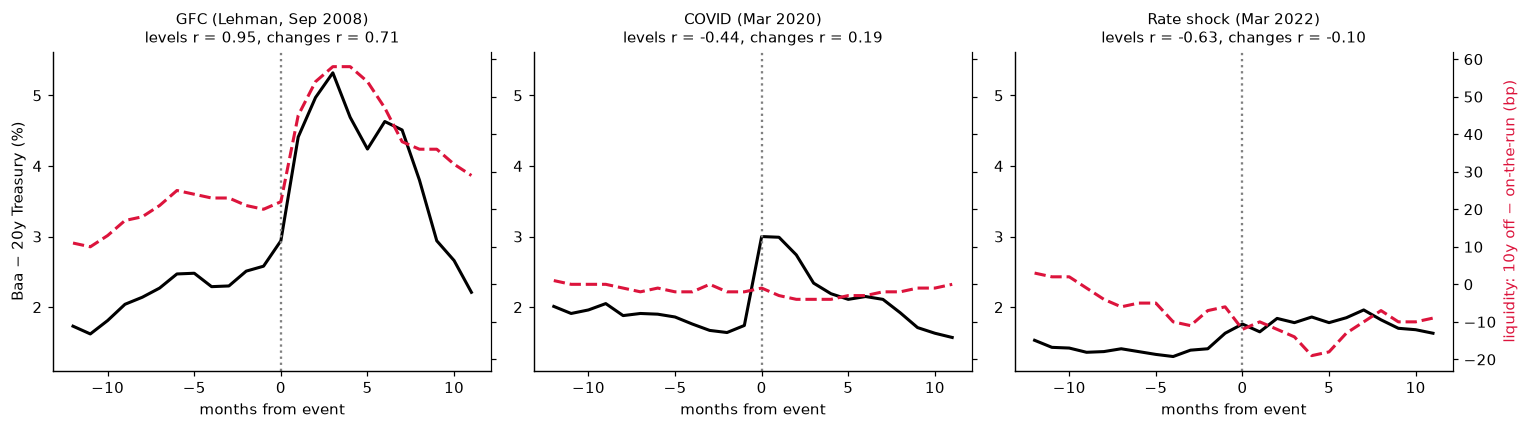

In [19]:
EVENTS = {"GFC": pd.Period("2008-09", "M"), "COVID": pd.Period("2020-03", "M"), "Rates": pd.Period("2022-03", "M")}
EP_LABEL = {"GFC": "GFC (Lehman, Sep 2008)", "COVID": "COVID (Mar 2020)", "Rates": "Rate shock (Mar 2022)"}

def ep_window(t0, lo=-12, hi=11):
    return P.loc[t0 + lo : t0 + hi, ["cs20", "liq10", "vix"]]

def link_stats(w, a="cs20", b="liq10"):
    d = w[[a, b]].dropna(); dd = d.diff().dropna()
    return {"N": len(d), "levels r": d[a].corr(d[b]), "levels rank r": d[a].rank().corr(d[b].rank()), "changes r": dd[a].corr(dd[b])}

WINDOWS = {
    "A. Main: 24m centred (t0-12..t0+11)": {k: (t - 12, t + 11) for k, t in EVENTS.items()},
    "B. 12m (t0-3..t0+8)":                 {k: (t - 3, t + 8) for k, t in EVENTS.items()},
    "C. 36m (t0-12..t0+23)":               {k: (t - 12, t + 23) for k, t in EVENTS.items()},
    "D. Acute 6m (t0..t0+5)":              {k: (t, t + 5) for k, t in EVENTS.items()},
    "E. Calendar 24m (2008-09, 2020-21, 2022-23)": {"GFC": (pd.Period("2008-01", "M"), pd.Period("2009-12", "M")),
                                                    "COVID": (pd.Period("2020-01", "M"), pd.Period("2021-12", "M")),
                                                    "Rates": (pd.Period("2022-01", "M"), pd.Period("2023-12", "M"))},
}
rows = [{"window": wl, "episode": k, **link_stats(P.loc[a:b])} for wl, spec in WINDOWS.items() for k, (a, b) in spec.items()]
ledger = pd.DataFrame(rows)
cols = pd.MultiIndex.from_product([["levels r", "levels rank r", "changes r"], list(EVENTS)])
t1 = ledger.pivot(index="window", columns="episode", values=["levels r", "levels rank r", "changes r"]).reindex(columns=cols)
display(t1)
print("Months per window (levels):", ledger.groupby("window")["N"].first().to_dict())
t1.to_csv(OUT / "table_episode_T1_windows.csv")

# figure: main windows on common axes
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
W = {k: ep_window(t) for k, t in EVENTS.items()}
cs_lim = (min(w["cs20"].min() for w in W.values()) - 0.2, max(w["cs20"].max() for w in W.values()) + 0.3)
lq_lim = (min(w["liq10"].min() for w in W.values()) - 4, max(w["liq10"].max() for w in W.values()) + 4)
x = np.arange(-12, 12)
for i, (ax, (k, t0)) in enumerate(zip(axes, EVENTS.items())):
    w = W[k]; ax.plot(x, w["cs20"].to_numpy(), color="black", lw=2); ax.set_ylim(*cs_lim)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.plot(x, w["liq10"].to_numpy(), color="crimson", ls="--", lw=2); ax2.set_ylim(*lq_lim)
    ax.axvline(0, color="grey", ls=":"); st = link_stats(w)
    ax.set_title(f"{EP_LABEL[k]}\nlevels r = {st['levels r']:.2f}, changes r = {st['changes r']:.2f}", fontsize=10)
    ax.set_xlabel("months from event")
    if i == 0: ax.set_ylabel("Baa − 20y Treasury (%)")
    if i < 2: ax2.set_yticklabels([])
    else: ax2.set_ylabel("liquidity: 10y off − on-the-run (bp)", color="crimson")
fig.tight_layout(); fig.savefig(OUT / "fig5_episodes_common_axes.png"); plt.show()

### 8.2 T2: is the later episodes' link *statistically* different from 2008's?
**What this does.** With 24 monthly points and persistent series, textbook correlation tests (Fisher z) are invalid. Instead we use a **circular block bootstrap**: resample blocks of 4 consecutive months (with their paired spread and liquidity values), recompute the correlation, repeat 5,000 times. This gives a confidence interval for each episode's correlation. The episodes do not overlap, so they are independent, and the bootstrap distribution of the *difference* (GFC minus later episode) tests whether 2008 is stronger. `p` = share of draws in which the difference is ≤ 0 (one-sided: "is the GFC link stronger?"). The seed is fixed, so results are reproducible.

In [20]:
rng = np.random.default_rng(301)

def block_boot_corr(x, y, block=4, B=5000):
    n = len(x); k = int(np.ceil(n / block)); out = np.empty(B)
    for i in range(B):
        starts = rng.integers(0, n, k)
        idx = ((starts[:, None] + np.arange(block)) % n).ravel()[:n]       # circular blocks keep short-run persistence
        xs, ys = x[idx], y[idx]
        out[i] = np.corrcoef(xs, ys)[0, 1] if xs.std() > 0 and ys.std() > 0 else np.nan
    return out

boot = {}
for k, t0 in EVENTS.items():
    d = ep_window(t0)[["cs20", "liq10"]].dropna(); dd = d.diff().dropna()
    boot[k] = {"levels": block_boot_corr(d["cs20"].to_numpy(), d["liq10"].to_numpy()),
               "changes": block_boot_corr(dd["cs20"].to_numpy(), dd["liq10"].to_numpy())}

ci_rows = []
for k in EVENTS:
    st = link_stats(ep_window(EVENTS[k]))
    for m, key in [("levels", "levels r"), ("changes", "changes r")]:
        lo, hi = np.nanpercentile(boot[k][m], [2.5, 97.5])
        ci_rows.append({"episode": k, "measure": m, "estimate": st[key], "95% CI low": lo, "95% CI high": hi})
ci = pd.DataFrame(ci_rows).set_index(["episode", "measure"]); print("Block-bootstrap 95% intervals (main 24-month windows)"); display(ci)

diff_rows = []
for k in ["COVID", "Rates"]:
    for m in ["levels", "changes"]:
        d_ = boot["GFC"][m] - boot[k][m]; d_ = d_[~np.isnan(d_)]
        diff_rows.append({"comparison": f"GFC − {k}", "measure": m, "observed difference": ci.loc[("GFC", m), "estimate"] - ci.loc[(k, m), "estimate"],
                          "95% CI low": np.percentile(d_, 2.5), "95% CI high": np.percentile(d_, 97.5), "p (GFC link not stronger)": np.mean(d_ <= 0)})
t2 = pd.DataFrame(diff_rows).set_index(["comparison", "measure"]); print("Is 2008 stronger than the later episode?"); display(t2)
ci.to_csv(OUT / "table_episode_T2_bootstrap_ci.csv"); t2.to_csv(OUT / "table_episode_T2_differences.csv")

Block-bootstrap 95% intervals (main 24-month windows)


estimate  95% CI low  95% CI high
episode measure                                   
GFC     levels      0.946       0.824        0.981
        changes     0.706      -0.028        0.944
COVID   levels     -0.441      -0.746        0.135
        changes     0.187      -0.187        0.427
Rates   levels     -0.631      -0.845       -0.204
        changes    -0.100      -0.430        0.266

Is 2008 stronger than the later episode?


observed difference  95% CI low  95% CI high  p (GFC link not stronger)
comparison  measure                                                                         
GFC − COVID levels                 1.386       0.797        1.679                      0.000
            changes                0.519      -0.251        0.996                      0.101
GFC − Rates levels                 1.576       1.126        1.792                      0.000
            changes                0.806      -0.022        1.226                      0.030

### 8.3 T3: pooled regression with episode interactions (controls for VIX)
**What this does.** Stacks the three episodes and estimates
$$\Delta cs_t=a+b_{G}\Delta liq_t+c_{G}\Delta VIX_t+\sum_{e\in\{COVID,Rates\}}\big(a_e+b_e\Delta liq_t+c_e\Delta VIX_t\big)D_e+\varepsilon_t ,$$
so the liquidity slope is $b_G$ in 2008 and $b_G+b_e$ in episode $e$. VIX is a control for general market stress, so the liquidity slopes are what remains *after* stress. A Wald test checks $b_{COVID}=b_{Rates}=0$ (slopes equal to 2008's). Standard errors are Newey-West (3 lags). Two versions: **monthly changes** (primary) and **levels with each episode demeaned** (equivalent to episode fixed effects).

In [21]:
def pooled_link(level, lags=3):
    parts = []
    for k, t0 in EVENTS.items():
        w = ep_window(t0).dropna()
        w = (w - w.mean()) if level else w.diff().dropna()                  # levels: demean within episode (fixed effects)
        w["episode"] = k; parts.append(w)
    Z = pd.concat(parts)
    for k in ["COVID", "Rates"]:
        e = (Z["episode"] == k).astype(float)
        Z[f"d_{k}"], Z[f"liq_x_{k}"], Z[f"vix_x_{k}"] = e, e * Z["liq10"], e * Z["vix"]
    X = sm.add_constant(Z[["liq10", "vix", "d_COVID", "d_Rates", "liq_x_COVID", "liq_x_Rates", "vix_x_COVID", "vix_x_Rates"]])
    fit = sm.OLS(Z["cs20"], X).fit(cov_type="HAC", cov_kwds={"maxlags": lags, "use_correction": True})
    out = {}
    for lab, expr in [("GFC", "liq10"), ("COVID", "liq10 + liq_x_COVID"), ("Rates", "liq10 + liq_x_Rates")]:
        t = fit.t_test(expr); out[lab] = {"liquidity slope (pp per bp)": float(np.squeeze(t.effect)), "HAC s.e.": float(np.squeeze(t.sd)), "p-value": float(np.squeeze(t.pvalue))}
    wald = fit.wald_test("liq_x_COVID = 0, liq_x_Rates = 0", use_f=True, scalar=True)
    return pd.DataFrame(out).T, float(wald.pvalue), int(fit.nobs)

t3 = {}
for lab, lvl in [("monthly changes (primary)", False), ("levels, episode-demeaned", True)]:
    tab, pw, n = pooled_link(lvl)
    print(f"{lab}: N = {n};  Wald test, liquidity slopes equal across episodes: p = {pw:.3f}"); display(tab)
    t3[lab] = (tab, pw)
    tab.assign(wald_p_equal_slopes=pw).to_csv(OUT / f"table_episode_T3_{'levels' if lvl else 'changes'}.csv")

monthly changes (primary): N = 69;  Wald test, liquidity slopes equal across episodes: p = 0.136


,liquidity slope (pp per bp),HAC s.e.,p-value
GFC,0.034,0.021,0.106
COVID,-0.033,0.040,0.398
Rates,-0.007,0.005,0.176


levels, episode-demeaned: N = 72;  Wald test, liquidity slopes equal across episodes: p = 0.000


,liquidity slope (pp per bp),HAC s.e.,p-value
GFC,0.050,0.007,0.000
COVID,-0.041,0.050,0.409
Rates,-0.009,0.005,0.067


### 8.4 T4: is 2008 unusual compared with every two-year window since 1986?
**What this does.** (a) Computes the correlation over *every* rolling 24-month window (levels and changes) and reports where the three event windows rank. (b) Cuts the whole sample into the 20 non-overlapping two-year windows and lists the correlation in each: if the 2008 link were a general feature of stress, other stressful windows (1998–99, 2000–01, 2020–21) would show it. This also shows how often a calm-period window produces a high *levels* correlation by accident, which is why changes matter.

,window end,levels r,percentile among all rolling windows (levels),changes r,percentile (changes)
GFC,2009-08,0.946,0.959,0.702,0.966
COVID,2021-02,-0.441,0.118,0.187,0.738
Rates,2023-02,-0.631,0.019,-0.119,0.295


All 466 rolling 24-month windows: median levels r = 0.04; share above 0.8 = 9.4%; above 0.9 = 7.7%; the windows above 0.9 are centred on 2007, 2008, 2009, 2010


,levels r,changes r,avg spread (pp),avg VIX
window,,,,
1986-01 to 1987-12,0.348,NaN,1.799,NaN
1988-01 to 1989-12,-0.299,NaN,1.729,NaN
1990-01 to 1991-12,-0.039,0.136,1.633,20.716
1992-01 to 1993-12,0.593,-0.146,1.233,14.078
1994-01 to 1995-12,-0.330,-0.268,1.147,13.159
1996-01 to 1997-12,-0.192,-0.240,1.174,19.445
1998-01 to 1999-12,0.511,0.077,1.545,25.001
2000-01 to 2001-12,-0.057,0.453,2.186,24.647
2002-01 to 2003-12,-0.058,0.087,1.955,24.647


Of 20 non-overlapping two-year windows, 2 have both levels r > 0.8 and changes r > 0.5: ['2006-01 to 2007-12', '2008-01 to 2009-12']
Windows with levels r > 0.5 but changes r < 0.2 (high levels correlation without month-to-month co-movement): ['1992-01 to 1993-12', '1998-01 to 1999-12', '2016-01 to 2017-12']


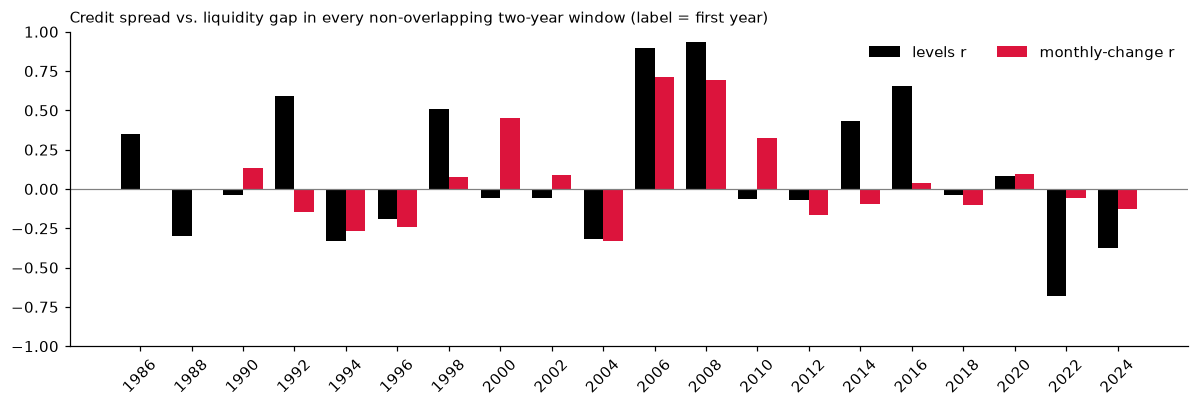

In [22]:
roll_l = P["cs20"].rolling(24).corr(P["liq10"])
roll_c = P["cs20"].diff().rolling(24).corr(P["liq10"].diff())
rl, rc = roll_l.dropna(), roll_c.dropna()
rank_rows = {k: {"window end": str(t0 + 11), "levels r": roll_l[t0 + 11], "percentile among all rolling windows (levels)": (rl < roll_l[t0 + 11]).mean(),
                 "changes r": roll_c[t0 + 11], "percentile (changes)": (rc < roll_c[t0 + 11]).mean()} for k, t0 in EVENTS.items()}
display(pd.DataFrame(rank_rows).T)
print(f"All {len(rl)} rolling 24-month windows: median levels r = {rl.median():.2f}; share above 0.8 = {(rl > 0.8).mean():.1%}; above 0.9 = {(rl > 0.9).mean():.1%}; "
      f"the windows above 0.9 are centred on {', '.join(sorted({str(i - 11)[:4] for i in rl.index[rl > 0.9]}))}")

led = []
for s0 in pd.period_range("1986-01", END, freq="M")[::24]:
    e0 = s0 + 23
    if e0 > END: break
    d = P.loc[s0:e0, ["cs20", "liq10", "vix"]]; dd = d.diff().dropna()
    led.append({"window": f"{s0} to {e0}", "levels r": d["cs20"].corr(d["liq10"]), "changes r": dd["cs20"].corr(dd["liq10"]),
                "avg spread (pp)": d["cs20"].mean(), "avg VIX": d["vix"].mean()})
led = pd.DataFrame(led).set_index("window"); led.to_csv(OUT / "table_episode_T4_ledger.csv")
display(led)
strong = led[(led["levels r"] > 0.8) & (led["changes r"] > 0.5)]
print(f"Of {len(led)} non-overlapping two-year windows, {len(strong)} have both levels r > 0.8 and changes r > 0.5: {list(strong.index)}")
print(f"Windows with levels r > 0.5 but changes r < 0.2 (high levels correlation without month-to-month co-movement): {list(led.index[(led['levels r'] > 0.5) & (led['changes r'] < 0.2)])}")

fig, ax = plt.subplots(figsize=(11, 3.8)); xs_ = np.arange(len(led)); wd = 0.38
ax.bar(xs_ - wd / 2, led["levels r"], wd, color="black", label="levels r"); ax.bar(xs_ + wd / 2, led["changes r"].fillna(0), wd, color="crimson", label="monthly-change r")
ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(xs_, [w[:4] for w in led.index], rotation=45); ax.set_ylim(-1, 1)
ax.set_title("Credit spread vs. liquidity gap in every non-overlapping two-year window (label = first year)", loc="left", fontsize=10); ax.legend(frameon=False, ncol=2)
fig.tight_layout(); fig.savefig(OUT / "fig6_two_year_ledger.png"); plt.show()

### 8.5 V1: can the proxy detect a liquidity event? (monthly and daily evidence)
**What this does.** A "no repeat" finding is only meaningful if the proxy would have *registered* a liquidity shock. (a) Lists the monthly proxy, a second proxy and the spread around each event. (b) Runs a **daily event study** (the monthly Treasury files cannot, but the FRED daily series can): the daily credit spread (Baa − 10y Treasury), the daily **TED spread** (a funding-liquidity measure, which ends Jan 2022) and the VIX, in a window from a month before to about three months after each event. For each series it reports the peak, the peak relative to the month before, and the daily correlation with the credit spread. The figure standardises each series within the window so shapes can be compared.

(a) Monthly values around each event (t0 - 1 ... t0 + 2):  liq10 and liq5 in bp, TED in bp, VIX in points


cs20   liq10   liq5     ted    vix
episode month                                      
GFC     2008-08 2.600  20.000 -5.000 108.200 20.700
        2008-09 2.900  22.000 -4.000 200.200 30.200
        2008-10 4.400  45.000 -1.000 335.300 61.200
        2008-11 5.000  54.000 -3.000 209.900 62.700
COVID   2020-02 1.700  -2.000  2.000  16.200 19.600
        2020-03 3.000  -1.000  8.000  81.500 57.700
        2020-04 3.000  -3.000  4.000  96.000 41.500
        2020-05 2.700  -4.000  5.000  27.500 30.900
Rates   2022-02 1.600  -6.000  4.000     NaN 25.700
        2022-03 1.800 -12.000  7.000     NaN 27.000
        2022-04 1.700 -10.000  5.000     NaN 24.400
        2022-05 1.800 -12.000  5.000     NaN 29.300

(b) Daily event study


peak   peak date  peak / prior-month mean  daily levels r with credit spread  daily changes r with credit spread
episode series                                                                                                                                          
GFC     credit spread (Baa − 10y, pp)  6.160  2008-12-04                    1.990                                NaN                                 NaN
        TED spread (pp)                4.580  2008-10-10                    4.131                              0.308                               0.145
        VIX                           80.860  2008-11-20                    3.403                              0.848                               0.294
COVID   credit spread (Baa − 10y, pp)  4.310  2020-03-23                    2.155                                NaN                                 NaN
        TED spread (pp)                1.420  2020-03-26                    4.428                              0.805                               0.431
        VIX                           82.690  2020-03-16                    6.046                              0.741                               0.254
Rates   credit spread (Baa − 10y, pp)  2.380  2022-03-10                    1.298                                NaN                                 NaN
        TED spread (pp)                  NaN     no data                      NaN                                NaN                                 NaN
        VIX                           36.450  2022-03-07                    1.676                              0.692                               0.134

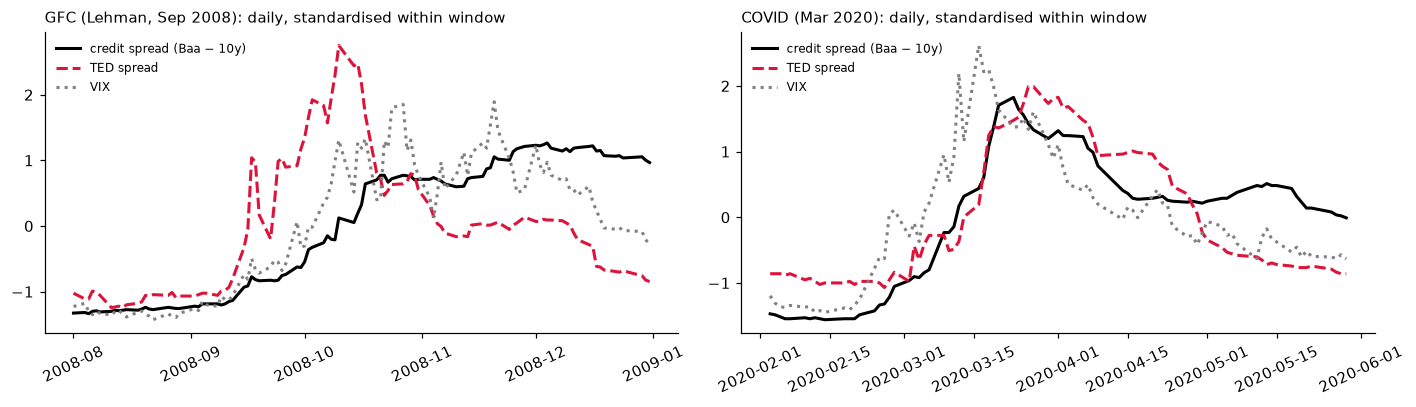

In [23]:
cols_m = ["cs20", "liq10", "liq5", "ted", "vix"]
around = pd.concat({k: P.loc[t0 - 1 : t0 + 2, cols_m] for k, t0 in EVENTS.items()}, names=["episode", "month"])
print("(a) Monthly values around each event (t0 - 1 ... t0 + 2):  liq10 and liq5 in bp, TED in bp, VIX in points"); display(around.round(1))

DE = pd.concat([fred["DBAA"], fred["DGS10"], fred["VIXCLS"], fred["TEDRATE"]], axis=1, sort=True)
DE["cs"] = DE["DBAA"] - DE["DGS10"]
DAILY = {"GFC": ("2008-08-01", "2008-12-31"), "COVID": ("2020-02-01", "2020-05-29"), "Rates": ("2022-02-01", "2022-06-30")}
rows = []
for k, (a, b) in DAILY.items():
    w = DE.loc[a:b]; pre = DE.loc[pd.Timestamp(a) - pd.Timedelta(days=45): pd.Timestamp(a) - pd.Timedelta(days=1)]
    ch = w[["cs", "VIXCLS", "TEDRATE"]].diff(); lv = w[["cs", "VIXCLS", "TEDRATE"]]
    for c, lab in [("cs", "credit spread (Baa − 10y, pp)"), ("TEDRATE", "TED spread (pp)"), ("VIXCLS", "VIX")]:
        s = w[c].dropna()
        if s.empty: rows.append({"episode": k, "series": lab, "peak": np.nan, "peak date": "no data", "peak / prior-month mean": np.nan, "daily levels r with credit spread": np.nan, "daily changes r with credit spread": np.nan}); continue
        rows.append({"episode": k, "series": lab, "peak": s.max(), "peak date": str(s.idxmax().date()), "peak / prior-month mean": s.max() / pre[c].mean(),
                     "daily levels r with credit spread": np.nan if c == "cs" else lv["cs"].corr(lv[c]), "daily changes r with credit spread": np.nan if c == "cs" else ch["cs"].corr(ch[c])})
t5 = pd.DataFrame(rows).set_index(["episode", "series"]); print("(b) Daily event study"); display(t5); t5.to_csv(OUT / "table_episode_V1_daily.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, k in zip(axes, ["GFC", "COVID"]):
    a, b = DAILY[k]; w = DE.loc[a:b, ["cs", "TEDRATE", "VIXCLS"]].dropna(); z = (w - w.mean()) / w.std()
    ax.plot(z.index, z["cs"], color="black", lw=2, label="credit spread (Baa − 10y)"); ax.plot(z.index, z["TEDRATE"], color="crimson", ls="--", lw=2, label="TED spread")
    ax.plot(z.index, z["VIXCLS"], color="grey", ls=":", lw=2, label="VIX"); ax.set_title(f"{EP_LABEL[k]}: daily, standardised within window", loc="left", fontsize=10)
    ax.tick_params(axis="x", rotation=25); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "fig7_daily_event_study.png"); plt.show()

### 8.6 V2: what repeats, if not the 10-year on/off-the-run gap?
**What this does.** Re-computes the link (main 24-month window, levels and monthly changes) for each candidate indicator against the Baa spread: the 10-, 5- and 2-year Treasury gaps, the TED spread (funding liquidity; available only to Jan 2022, so only partly for 2022–23) and the VIX (general stress, Merton default-risk proxy). Cells with fewer than 12 months of overlap are blank.

In [24]:
PROXIES = {"liq10": "10y on/off-the-run gap (main)", "liq5": "5y gap", "liq2": "2y gap", "ted": "TED spread (funding liquidity)", "vix": "VIX (general stress)"}
rows = []
for pc, pl in PROXIES.items():
    row = {"indicator": pl}
    for k, t0 in EVENTS.items():
        w = P.loc[t0 - 12 : t0 + 11, ["cs20", pc]].dropna(); dd = w.diff().dropna()
        ok = len(w) >= 12
        row[(k, "N")] = len(w); row[(k, "levels r")] = w["cs20"].corr(w[pc]) if ok else np.nan; row[(k, "changes r")] = dd["cs20"].corr(dd[pc]) if ok else np.nan
    rows.append(row)
t6 = pd.DataFrame(rows).set_index("indicator"); t6.columns = pd.MultiIndex.from_tuples(t6.columns)
t6 = t6.reindex(columns=pd.MultiIndex.from_product([list(EVENTS), ["N", "levels r", "changes r"]]))
display(t6); t6.to_csv(OUT / "table_episode_V2_alt_proxies.csv")

GFC                    COVID                    Rates                   
                                 N levels r changes r     N levels r changes r     N levels r changes r
indicator                                                                                              
10y on/off-the-run gap (main)   24    0.946     0.706    24   -0.441     0.187    24   -0.631    -0.100
5y gap                          24    0.097    -0.034    24    0.700     0.654    24    0.827     0.180
2y gap                          24   -0.653    -0.442    24   -0.272     0.060    24    0.113     0.160
TED spread (funding liquidity)  24    0.220     0.486    24    0.666     0.734    11      NaN       NaN
VIX (general stress)            24    0.904     0.694    24    0.811     0.860    24    0.831     0.720

### Findings: does the 2008 link repeat?
**Answer: for the 10-year on/off-the-run gap used on slide 59, 2008 is a one-off. The link does not repeat in March 2020 or in the 2022–23 rate shock. What does repeat is a broader pattern: credit spreads move with market stress (VIX) in every episode, and with funding liquidity (TED) in 2020.**

1. **T1: the result does not depend on how the window is cut.** The 2008 link is strong under all five windows: levels r 0.92–0.95 and changes r 0.69–0.95. For COVID the levels correlation is −0.44 to +0.55 depending on the window (+0.55 only in the six-month window, N = 6) and the change correlation −0.24 to +0.32, so the sign is unstable and it is never near 0.9. For the rate shock the levels correlation is negative under all five windows (−0.40 to −0.68).
2. **T2: in levels, 2008 is significantly stronger; in changes the test has little power.** GFC − COVID in levels = 1.39 (95 % bootstrap interval 0.80 to 1.68, p < 0.001) and GFC − rate shock = 1.58 (1.13 to 1.79, p < 0.001). In monthly changes the differences are smaller and weaker evidence: vs. COVID 0.52 (−0.25 to 1.00, p = 0.10), vs. rate shock 0.81 (−0.02 to 1.23, p = 0.03). With 23 changes even 2008's own change correlation (0.71) has a wide interval (−0.03 to 0.94).
3. **T3: same picture after controlling for VIX.** Liquidity slope (pp of spread per bp): 0.034 in 2008 (p = 0.11), −0.033 in COVID, −0.007 in the rate shock. Equality of slopes is rejected in levels with episode fixed effects (p < 0.001; 0.050 vs. −0.041 and −0.009) but not in changes (p = 0.14). So the evidence for "does not repeat" is strong in levels and suggestive in changes.
4. **T4: 2008 stands out from every two-year window since 1986.** The 2008–09 window ranks at the 96th (levels) and 97th (changes) percentile of all 466 rolling 24-month windows; the COVID window at the 12th/74th and the rate-shock window at the 2nd/30th. Every window with r > 0.9 (7.7 % of all) is centred on 2007–2010. Only 2 of 20 non-overlapping two-year windows have levels r > 0.8 and changes r > 0.5, and both belong to the same crisis (2006–07 and 2008–09). Three calm periods (1992–93, 1998–99, 2016–17) show levels r of 0.5–0.66 with changes r near zero, which is why levels alone are misleading.
5. **V1: part of the "no repeat" is the proxy failing to see 2020.** In March 2020 the 10-year gap does not move (−2 to −1 bp), but monthly TED rises from 16 to 82 bp and the 5-year gap from 2 to 8 bp. In the daily event study TED peaks at 4.4× its prior-month level (26 Mar), three days after the credit-spread peak (23 Mar), and the daily credit-spread–TED correlation in the COVID window (levels 0.81, changes 0.43) is stronger than in the 2008 window (0.31, 0.15). The daily and monthly evidence therefore shows a credit–funding-liquidity link in 2020 that the 10-year on/off-the-run gap cannot detect.
6. **V2: what repeats.** Link to the Baa spread (levels r / changes r), main 24-month windows:

| Indicator | 2008 | COVID | Rate shock |
|---|---|---|---|
| 10y on/off-the-run gap (slide 59) | 0.95 / 0.71 | −0.44 / 0.19 | −0.63 / −0.10 |
| 5y gap | 0.10 / −0.03 | 0.70 / 0.65 | 0.83 / 0.18 |
| TED (funding liquidity) | 0.22 / 0.49 | 0.67 / 0.73 | not testable (series ends Jan 2022) |
| **VIX (general stress)** | **0.90 / 0.69** | **0.81 / 0.86** | **0.83 / 0.72** |

So the credit–stress link is present in all three episodes, while no single liquidity gauge works in all three: the 10-year gap works in 2008 only, the 5-year gap in the later episodes only, and TED in 2020.

**Caveats.** Each episode has 24 months (23 changes) of persistent data, so intervals are wide; the episodes are not clean natural experiments (the Fed intervened in 2008 and 2020, and 2022–23 includes the March 2023 banking stress); VIX measures stress, not liquidity; TED is partly driven by the flight into T-bills and by LIBOR credit risk. The answer is a statement about *these three episodes and these proxies*, not about every crisis.

## 9. Conclusion

**Answer to the research question.** *Slide 59's 0.96 reproduces (0.967 on our data; 0.956 from the slide's own chart data), but 2008's link between the 10-year on/off-the-run liquidity gap and the Baa spread is a one-off.* It does not repeat in March 2020 (levels r −0.44 to +0.55 depending on the window, never near 0.9) or in the 2022–23 rate shock (negative in every window); it is significantly stronger in 2008 in levels (p < 0.001) and only suggestively stronger in monthly changes; and 2008–09 is the only two-year window since 1986 with strong levels *and* change correlations. Over the longest sample the correlation is 0.47, excluding 2007–09 it is 0.11. Two qualifications keep this from being "liquidity does not matter in later crises": the 10-year gap is blind to March 2020 (it moves by 1 bp while TED, a funding-liquidity measure, rises about five-fold), and the broader pattern *does* repeat, since the credit spread moves with VIX in all three episodes (levels r 0.81–0.90, changes r 0.69–0.86) and with TED in 2020 (daily levels r 0.81).

**How much of the Baa spread is liquidity vs. default risk?** VIX (default-risk proxy) explains about twice as much of the spread's variation as the liquidity gap (R² 0.42 vs. 0.23; 0.46 together), with the sign the Merton model predicts. Over 1990–2026 the average Baa spread (1.73 pp) is about 14× the expected default loss (0.124 pp); liquidity accounts for only about 6–12 % of the 1.6 pp left over (an illustrative bound, not a causal split), more in a crisis (about 27 % of the spread in 2008–09). Most of the spread is explained by neither factor, which is the credit-spread puzzle.

**For central-bank staff:** do not treat a Treasury on/off-the-run gap as a general indicator of corporate-credit stress. It signalled 2008 but was silent in 2020 and 2022–23; funding-liquidity (TED-type) and volatility (VIX) measures tracked the spread in more of the episodes, and no single indicator worked in all three. **For corporate-bond fund managers:** only a small part of the premium earned in normal times is compensation for illiquidity, and volatility is a better guide to spread movements than a Treasury liquidity gap.

**Limitations.** The liquidity measure is a fitted-curve proxy, rounded to 1 bp and negative from 2019 on; the slide's own spread series is a more volatile, unidentified index (our spread levels differ by maturity matched), though its shape matches ours (corr 0.97–0.99); each episode has only 24 persistent months, so change-based tests have low power; the episodes are affected by policy responses and (2023) banking stress; VIX measures stress, not default risk alone; and the puzzle uses the lecture's Moody's loss and recovery numbers rather than raw Moody's data.


### Requirement checklist

| # | Requirement | Where |
|---|---|---|
| 1 | Economic question and audience | Title cell, Section 8 |
| 2 | Source/construct Baa–Treasury spread and liquidity proxy; document | Section 1, 2.3 |
| 3 | Maturity match, units, frequency | Sections 1, 2.3 (Baa 20y+ vs 20y Treasury; pp and bp; monthly average) |
| 4 | Missing values, duplicates, outliers, alignment, winsorizing, counts | Sections 2.1–2.5 (cleaning log) |
| 5 | Dual-axis plot and correlation, slide window | Section 3.1 |
| 6 | Extended sample | Section 3.2 |
| 7 | Comparison with slide (0.96) | Section 4 |
| 8 | Liquidity vs. VIX regressions, slide-51 comparison | Section 5 |
| 9 | Credit-spread puzzle | Section 6 |
| 10 | Sensitivity (sub-periods, levels vs changes, maturity, proxy, frequency, winsorizing) | Section 7 |
| RQ | Does the 2008 link repeat in 2020 and 2022–23? (window robustness, bootstrap, pooled regression, benchmark ledger, daily validation, alternative indicators) | Section 8 |

### Reproducibility
Inputs: only the files in `data/` (relative paths). Python 3.13; pandas 3.1.1, numpy 2.5.4, matplotlib 3.11.2, statsmodels 0.15.0, scipy 1.18.1, xlrd 2.0.2 (see `requirements.txt` and `README.md`). Run all cells from a clean kernel; outputs are written to `output/`.